# Per-station overview (Alaska)

**Two pages per station** -- one for NISAR, one for Sentinel-1 -- each
pulling together everything this project has computed for that satellite:
NDVI/in-situ SM, De Zan coherence/closure-phase vs. in-situ SM (each track
with its own regression trend line), and the estimated-vs-in-situ SM
timeseries (SME2+NISAR, or S1 alone). A page is skipped entirely if that
satellite has no coherence/closure/estimate data at all for the station.

**Track colors and incidence angle live in one shared legend strip below
the 2x2 panel grid** (not a subtitle, not the scatter plots' own legend,
and not its own grid cell of mostly-empty whitespace) -- one swatch +
incidence angle per track, built from every track that appears anywhere
for that satellite (coherence, closure, or estimates), so a track never
silently disappears from the legend just because it happens to have no
scatter points. Both NISAR and S1 points are plotted as circles.

**Tracks with dead coherence are dropped everywhere, including the
estimate-timeseries panel.** A track whose coherence-pair rows are *all*
NaN (every acquisition's saved GSLC window had its pixel mask flag the
whole window invalid) has no usable signal anywhere for that track --
coherence, closure phase, or a trustworthy SM estimate -- even though the
inversion output may still carry rows for it. `_tracks_with_dead_coherence`
excludes these from the legend, the estimate-timeseries scatter, and the
shared x-axis date range, rather than letting them appear ungrounded (this
was previously visible as, e.g., McGrath's NISAR track 44 or
PilgrimHotSprings' track 35 showing up in the estimate timeseries with no
corresponding scatter points or legend entry).

**Scatter-plot dot size is a significance signal, not a legend key**: in the
coherence panel, size scales with temporal baseline (shortest baseline =
biggest dot, longest = smallest-but-visible); in the closure-phase panel,
size scales with the triplet's minimum pairwise coherence (higher = bigger
dot). Both size scales are **fixed across every station/page** (baseline
against the global min/max seen anywhere in `stations_to_plot`, min-coherence
against its natural [0, 1] bound) -- not rescaled per page -- so the same
dot size always means the same underlying value, and a station where the
best min-coherence is only 0.2 shows uniformly small dots rather than that
0.2 being stretched to look like the biggest one on the page. Each scatter
panel's own legend shows only that size-to-value mapping -- track identity
is the shared legend strip's job.

**Per-station, not fixed across stations**: axis ranges auto-scale to each
station's own data, except NDVI (0.2-1), coherence (0-1), and closure phase
(0-pi rad), which are always the same scale so panels are comparable at a
glance -- as is dot size (above). The NDVI panel and the estimate-timeseries
panel both plot Volumetric Soil Moisture (%) on their left axis, and that
axis is synced to the same range across *every* such panel for a station --
its NDVI panel(s) and both its NISAR and S1 estimate-timeseries panels all
share one y-range, computed after both pages are built, so a reader can
compare SM magnitude directly between a station's NISAR and S1 pages, not
just within one page. Track colors are only kept consistent *within* one
station's own pages, not across stations, and never reuse green -- reserved
for NDVI so a green track dot can't be mistaken for an NDVI point (see
`build_track_color_map`, Section 7). Stations with no SM estimate at
all are skipped entirely, and a station with no NDVI coverage skips that
one panel.

**In-situ gating**: an estimate, coherence pair, or closure triplet is only
plotted if every acquisition it depends on has a valid (gap-free) in-situ
interpolation at that date -- otherwise there's no SM difference/range to
compare it against. The estimate-timeseries x-axis is stretched to the
first/last *in-situ-covered* estimate across both satellites, +/- 24h.

**Depth: 5cm only**, all points, **no quality/fault filtering** on the
in-situ series (this project's `read_insitu` no longer does any). NDVI and
in-situ SM are plotted as points only, never interpolated/connected.

**Figure size: 15x9 in (~10:6), one slide each** -- sized to drop straight
into a Google Slides deck without further cropping.

**Data sources** (all precomputed by other notebooks in this project -- this
notebook only reads and plots, no new computation except station terrain):
- In-situ SM: `ismn_data/alaska/station_data/{station}_ts_0.05.csv`
- NDVI: `nisar_data/alaska_HLS_ndvi/{station}_HLS_ndvi.csv`
- NISAR coherence/closure: `nisar_data/alaska_GSLC_coherence_closure/{station}_NISAR_GSLC_*.csv`
- Sentinel-1 coherence/closure: `S1_coherence_closure_alaska/{station}_orbit*_S1_*.csv`
- SME2: `SME2_data_alaska/sme2_cache.csv`
- NISAR/S1 SM estimates: `nisar_data/alaska_NISAR_SM_estimates.csv` / `S1_SM_estimates_alaska.csv`
  (written by the export cell at the end of `NISAR_SM_alaska.ipynb` /
  `S1_SM_alaska.ipynb` -- **re-run those two notebooks first** if you want
  this page to reflect a fresh inversion run)
- Station terrain (slope): computed here directly from Copernicus GLO-30,
  the same way `Earsel26_NISAR-main/util/nisar_station_timeseries.py`'s
  `compute_station_terrain` does for the GCOV backscatter pipeline -- no
  Earthdata credentials needed, just public DEM tiles.

In [1]:
import sys
import os
from pathlib import Path

import pyproj
pyproj.datadir.set_data_dir(os.path.join(sys.prefix, "Library", "share", "proj"))


def require_globals(*names):
    missing = [n for n in names if n not in globals()]
    if missing:
        raise RuntimeError(
            f"Missing {missing} -- run the earlier setup cells first "
            "(the kernel may have been restarted)."
        )


BASE = Path.cwd()
EARSEL_NOTEBOOKS = BASE / "Earsel26_NISAR-main" / "notebooks"
EARSEL_ROOT = EARSEL_NOTEBOOKS.parent
if str(EARSEL_ROOT) not in sys.path:
    sys.path.append(str(EARSEL_ROOT))

COH_CLOSURE_DIR = EARSEL_NOTEBOOKS / "nisar_data" / "alaska_GSLC_coherence_closure"
NDVI_DIR = EARSEL_NOTEBOOKS / "nisar_data" / "alaska_HLS_ndvi"
INSITU_DIR = EARSEL_NOTEBOOKS / "ismn_data" / "alaska" / "station_data"
S1_COH_CLOSURE_DIR = BASE / "S1_coherence_closure_alaska"
SME2_CACHE_PATH = BASE / "SME2_data_alaska" / "sme2_cache.csv"
NISAR_SM_ESTIMATES_PATH = EARSEL_NOTEBOOKS / "nisar_data" / "alaska_NISAR_SM_estimates.csv"
S1_SM_ESTIMATES_PATH = BASE / "S1_SM_estimates_alaska.csv"

import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.lines import Line2D

DATE_FORMATTER = mdates.DateFormatter("%b %d")

DEPTH_MAIN = 0.05
MAX_GAP_HOURS = 6
# Same safeguard Checks_alaska.ipynb/Checks_alaska_S1.ipynb use: a same-pass
# adjacent-frame pair/triplet leg can have a temporal baseline of seconds,
# which would otherwise show up as a near-zero-dSM point that's structurally
# guaranteed to look uninformative, not a real test of anything.
MIN_BASELINE_DAYS = 0.01

SENSOR_MARKER = {"NISAR": "o", "S1": "o"}
SIZE_MIN = 12
SIZE_MAX = 160
ALPHA_DOTS = 0.7
ALPHA_LEGEND = 0.75

FONT_SUPTITLE = 16
FONT_PANEL_TITLE = 11
FONT_AXIS_LABEL = 10
FONT_TICK = 9
FONT_LEGEND = 9

# tab10 with green (index 2) dropped -- reserved for NDVI, see build_track_color_map
TRACK_COLOR_PALETTE = [c for i, c in enumerate(plt.cm.tab10(np.linspace(0, 1, 10))) if i != 2]


C:\Users\geoka\miniconda3\envs\nisar-era5\Lib\site-packages\pyproj\network.py:59: UserWarning: pyproj unable to set PROJ database path.
  _set_context_ca_bundle_path(ca_bundle_path)


## 1. Station list

In [2]:
require_globals("EARSEL_NOTEBOOKS")

stations_path = EARSEL_NOTEBOOKS / "ismn_data" / "alaska" / "stations.geojson"
with open(stations_path) as f:
    stations_geojson = json.load(f)

stations = {
    feat["properties"]["station_val"]: (
        feat["geometry"]["coordinates"][1],  # lat
        feat["geometry"]["coordinates"][0],  # lon
    )
    for feat in stations_geojson["features"]
}
print(f"Loaded {len(stations)} stations")


Loaded 20 stations


## 2. Data readers

Every reader returns `None` (or an empty DataFrame) when a station has no
file for that source -- every plot function below handles that by simply
leaving its panel empty, not by raising.

In [3]:
require_globals("INSITU_DIR", "NDVI_DIR", "COH_CLOSURE_DIR", "S1_COH_CLOSURE_DIR")


def read_insitu(station, depth=DEPTH_MAIN):
    path = INSITU_DIR / f"{station}_ts_{depth:.2f}.csv"
    if not path.exists():
        return None
    df = pd.read_csv(path, index_col=0, parse_dates=True)
    return df.iloc[:, 0].sort_index()  # single sm_<depth> column, whatever it's named


def interp_insitu_at(series, ts):
    before = series.loc[:ts]
    after = series.loc[ts:]
    if before.empty or after.empty:
        return np.nan
    t0, v0 = before.index[-1], before.iloc[-1]
    t1, v1 = after.index[0], after.iloc[0]
    if t0 == t1:
        return float(v0)
    gap_hours = (t1 - t0).total_seconds() / 3600.0
    if gap_hours > MAX_GAP_HOURS:
        return np.nan
    frac = (ts - t0).total_seconds() / (t1 - t0).total_seconds()
    return float(v0 + frac * (v1 - v0))


def _sm_diff_pct(df, series, col_a, col_b):
    a = df[col_a].apply(lambda ts: interp_insitu_at(series, ts))
    b = df[col_b].apply(lambda ts: interp_insitu_at(series, ts))
    return (a - b).abs() * 100


def _sm_range_pct(df, series, cols):
    vals = pd.concat([df[c].apply(lambda ts: interp_insitu_at(series, ts)) for c in cols], axis=1)
    return (vals.max(axis=1, skipna=False) - vals.min(axis=1, skipna=False)) * 100


def read_ndvi(station):
    path = NDVI_DIR / f"{station}_HLS_ndvi.csv"
    if not path.exists():
        return None
    df = pd.read_csv(path, parse_dates=["target_date"])
    df = df[df["n_valid_px"] > 0]
    if df.empty:
        return None
    return df.set_index("target_date")["ndvi_mean"].sort_index()


def read_nisar_coherence(station):
    path = COH_CLOSURE_DIR / f"{station}_NISAR_GSLC_coherence.csv"
    if not path.exists():
        return None
    df = pd.read_csv(path, parse_dates=["date_1", "date_2"])
    return df[df["temporal_baseline_days"] >= MIN_BASELINE_DAYS].copy()


def read_nisar_closure(station):
    path = COH_CLOSURE_DIR / f"{station}_NISAR_GSLC_closure_phase.csv"
    if not path.exists():
        return None
    df = pd.read_csv(path, parse_dates=["date_1", "date_2", "date_3"])
    keep = (
        (df["temporal_baseline_12_days"] >= MIN_BASELINE_DAYS)
        & (df["temporal_baseline_23_days"] >= MIN_BASELINE_DAYS)
        & (df["temporal_baseline_13_days"] >= MIN_BASELINE_DAYS)
    )
    return df[keep].copy()


def read_s1_coherence(station):
    dfs = [pd.read_csv(p, parse_dates=["date_1", "date_2"])
           for p in sorted(S1_COH_CLOSURE_DIR.glob(f"{station}_orbit*_S1_coherence.csv"))]
    if not dfs:
        return None
    df = pd.concat(dfs, ignore_index=True)
    return df[df["temporal_baseline_days"] >= MIN_BASELINE_DAYS].copy()


def read_s1_closure(station):
    dfs = [pd.read_csv(p, parse_dates=["date_1", "date_2", "date_3"])
           for p in sorted(S1_COH_CLOSURE_DIR.glob(f"{station}_orbit*_S1_closure_phase.csv"))]
    if not dfs:
        return None
    df = pd.concat(dfs, ignore_index=True)
    keep = (
        (df["temporal_baseline_12_days"] >= MIN_BASELINE_DAYS)
        & (df["temporal_baseline_23_days"] >= MIN_BASELINE_DAYS)
        & (df["temporal_baseline_13_days"] >= MIN_BASELINE_DAYS)
    )
    return df[keep].copy()


## 3. SME2 and SM-estimate tables

In [4]:
sme2_df = (
    pd.read_csv(SME2_CACHE_PATH, parse_dates=["timestamp"])
    if SME2_CACHE_PATH.exists() else pd.DataFrame(columns=["station", "timestamp", "sm_pct"])
)
nisar_est_df = pd.read_csv(NISAR_SM_ESTIMATES_PATH, parse_dates=["date"])
s1_est_df = pd.read_csv(S1_SM_ESTIMATES_PATH, parse_dates=["date"])


def read_sme2(station):
    sub = sme2_df[sme2_df["station"] == station]
    if sub.empty:
        return None
    return sub.set_index("timestamp")["sm_pct"].sort_index()


def read_nisar_estimates(station, depth_label="5cm"):
    return nisar_est_df[(nisar_est_df["station"] == station) & (nisar_est_df["depth"] == depth_label)]


def read_s1_estimates(station, depth_label="5cm"):
    return s1_est_df[(s1_est_df["station"] == station) & (s1_est_df["depth"] == depth_label)]


print(f"SME2 cache: {sme2_df['station'].nunique()} station(s), {len(sme2_df)} row(s)")
print(f"NISAR SM estimates: {len(nisar_est_df)} row(s)")
print(f"S1 SM estimates: {len(s1_est_df)} row(s)")


SME2 cache: 7 station(s), 188 row(s)
NISAR SM estimates: 732 row(s)
S1 SM estimates: 224 row(s)


## 4. Station terrain (slope)

Reuses `Earsel26_NISAR-main/util/nisar_station_timeseries.py`'s own
`compute_station_terrain` -- a 3x3 Copernicus GLO-30 window per station,
Horn's-method slope/aspect, streamed from the public DEM bucket (no
Earthdata login needed, unlike the GCOV/GSLC pipeline itself).

In [5]:
require_globals("EARSEL_ROOT", "stations")

from util.nisar_station_timeseries import compute_station_terrain

station_dicts = [{"name": name, "lon": lon, "lat": lat} for name, (lat, lon) in stations.items()]
compute_station_terrain(station_dicts)
slope_by_station = {d["name"]: d["dem_slope_deg"] for d in station_dicts}
elevation_by_station = {d["name"]: d["dem_elevation_m"] for d in station_dicts}


Computing local terrain slope/aspect from Copernicus GLO-30 for each station...


Done. 18 unique DEM tiles used for 20 stations.
Slope range across stations: 0.51 - 9.41 deg (median 1.42 deg)


## 5. Stations to plot

Drops any station with no SM estimate at all (neither NISAR nor S1, at
5cm) -- there's nothing to show in half the page for these, and it's
usually an upstream data gap (e.g. missing SoilGrids texture, or no usable
coherence/closure data), not something this notebook can fix.

In [6]:
require_globals("stations", "read_nisar_estimates", "read_s1_estimates")

stations_to_plot = sorted(
    s for s in stations
    if not read_nisar_estimates(s).empty or not read_s1_estimates(s).empty
)
skipped = sorted(set(stations) - set(stations_to_plot))
print(f"{len(stations_to_plot)}/{len(stations)} station(s) have at least one 5cm SM estimate -- plotting those")
if skipped:
    print(f"Skipped (no NISAR or S1 estimate): {skipped}")


16/20 station(s) have at least one 5cm SM estimate -- plotting those
Skipped (no NISAR or S1 estimate): ['Aniak', 'MooseInc', 'Nenana', 'PrudhoeBay']


## 6. Global temporal-baseline range

Coherence-panel dot size (Section 7) is scaled against a *fixed* baseline
range shared by every station/page, computed once here across all of
`stations_to_plot` -- so dot size means the same baseline length
everywhere, not a per-page rescaled one. The closure panel's min-coherence
sizing needs no such scan: coherence is already bounded to [0, 1].

In [7]:
require_globals("stations_to_plot")

_baseline_cols = []
for _station in stations_to_plot:
    for _df in (read_nisar_coherence(_station), read_s1_coherence(_station)):
        if _df is not None and not _df.empty:
            _baseline_cols.append(_df["temporal_baseline_days"].dropna())

GLOBAL_BASELINE_MIN = min(s.min() for s in _baseline_cols)
GLOBAL_BASELINE_MAX = max(s.max() for s in _baseline_cols)
print(f"Global temporal baseline range for dot sizing: "
      f"{GLOBAL_BASELINE_MIN:.2f}-{GLOBAL_BASELINE_MAX:.2f} days")


Global temporal baseline range for dot sizing: 12.00-79.00 days


## 7. Per-(station, satellite) track color map

One color per track/orbit, built fresh for each station+satellite page (not
once globally) from the *union* of tracks appearing in that satellite's
coherence data, closure data, and SM estimates -- so a track that (for
example) only ever appears in the estimates table still gets a stable color
and a legend entry, instead of silently falling back to gray and vanishing
from the legend.

In [8]:
def _tracks_with_dead_coherence(station, sensor):
    """Tracks that have coherence-pair rows but where *every* one of them is
    NaN -- i.e. every acquisition's saved GSLC window had its mask flag every
    pixel invalid (0/255), so there's no usable signal for this track
    anywhere (coherence, closure phase, or the estimate timeseries), even
    though the SM-inversion output may still carry rows for it. Distinct from
    a track with *no* coherence rows at all (too few acquisitions to form a
    pair) -- that's a normal, unflagged absence, not this."""
    if sensor == "NISAR":
        df, coh_col, track_col = read_nisar_coherence(station), "coherence_HH", "orbit_num"
    else:
        df, coh_col, track_col = read_s1_coherence(station), "coherence_VV", "orbit"
    if df is None or df.empty:
        return set()
    return {track for track, g in df.groupby(track_col) if g[coh_col].notna().sum() == 0}


def _sensor_all_tracks(station, sensor):
    if sensor == "NISAR":
        coh, clo, est = read_nisar_coherence(station), read_nisar_closure(station), read_nisar_estimates(station)
        coh_col = clo_col = "orbit_num"
        est_col = "track"
    else:
        coh, clo, est = read_s1_coherence(station), read_s1_closure(station), read_s1_estimates(station)
        coh_col = clo_col = est_col = "orbit"
    tracks = set()
    if coh is not None and not coh.empty:
        tracks |= set(coh[coh_col].unique())
    if clo is not None and not clo.empty:
        tracks |= set(clo[clo_col].unique())
    if est is not None and not est.empty:
        tracks |= set(est[est_col].unique())
    tracks -= _tracks_with_dead_coherence(station, sensor)
    return tracks


def _sensor_incidence_by_track(station, sensor):
    if sensor == "NISAR":
        coh, clo, track_col = read_nisar_coherence(station), read_nisar_closure(station), "orbit_num"
    else:
        coh, clo, track_col = read_s1_coherence(station), read_s1_closure(station), "orbit"
    result = {}
    if coh is not None and not coh.empty:
        result.update(coh.groupby(track_col)["local_incidence_angle_deg"].mean().to_dict())
    if clo is not None and not clo.empty and "local_incidence_angle_deg" in clo.columns:
        for track, v in clo.groupby(track_col)["local_incidence_angle_deg"].mean().items():
            result.setdefault(track, v)
    return result


def build_track_color_map(track_ids):
    """tab10 with green (index 2) dropped -- green is already reserved for
    NDVI in the NDVI panel, so reusing it for a track color would make a
    green track dot easy to mistake for an NDVI point. Falls back to turbo,
    skipping its green band (~0.25-0.45), only past 9 tracks (not seen in
    this dataset -- the most any one station/satellite has is 6)."""
    ids = sorted(track_ids)
    n = len(ids)
    if n == 0:
        return {}
    if n <= len(TRACK_COLOR_PALETTE):
        colors = TRACK_COLOR_PALETTE[:n]
    else:
        fracs = np.concatenate([np.linspace(0, 0.22, n - n // 2), np.linspace(0.48, 1.0, n // 2)])
        colors = plt.cm.turbo(fracs)
    return dict(zip(ids, colors))


## 8. Panel functions

One function per panel type. Nothing here sets a fixed axis range except
NDVI, coherence, and closure phase (Section 8's intro), which stay on a
common scale across every station for comparability.

In [9]:
def _size_from_range(values, lo, hi, invert):
    """Map a data column to marker sizes in [SIZE_MIN, SIZE_MAX], against a
    *fixed* (lo, hi) range shared across every station/page -- not each
    page's own min/max -- so the same dot size means the same value on
    every page (e.g. a station whose best min-coherence is only 0.2 gets
    uniformly tiny dots, instead of that 0.2 being rescaled to "biggest").

    invert=True: smallest value -> biggest dot (used for temporal baseline,
    where the shortest baseline is the most significant pair).
    invert=False: biggest value -> biggest dot (used for min-coherence,
    where the most coherent triplet is the most trustworthy).
    """
    values = np.asarray(values, dtype=float)
    if hi == lo:
        return np.full(values.shape, (SIZE_MIN + SIZE_MAX) / 2)
    frac = np.clip((values - lo) / (hi - lo), 0, 1)
    if invert:
        frac = 1 - frac
    return SIZE_MIN + frac * (SIZE_MAX - SIZE_MIN)


def _size_legend(ax, lo, hi, invert, fmt, title):
    if not np.isfinite(lo) or not np.isfinite(hi):
        return
    ref_vals = [lo, hi] if hi == lo else [lo, (lo + hi) / 2, hi]
    sizes = _size_from_range(np.array(ref_vals), lo, hi, invert)
    handles = [ax.scatter([], [], s=s, color="gray", alpha=ALPHA_LEGEND,
                           edgecolor="black", linewidth=0.4) for s in sizes]
    labels = [fmt(v) for v in ref_vals]
    ax.legend(handles, labels, title=title, fontsize=FONT_LEGEND, title_fontsize=FONT_LEGEND,
              loc="best", framealpha=ALPHA_LEGEND)


In [10]:
def plot_ndvi_insitu(ax, station, xlim):
    ax2 = ax.twinx()
    series = read_insitu(station)
    if series is not None:
        ax.scatter(series.index, series.values * 100, color="black", s=4, alpha=0.4,
                   label="in-situ SM", zorder=2)
    ndvi = read_ndvi(station)
    if ndvi is not None:
        ax2.scatter(ndvi.index, ndvi.values, color="tab:green", s=18, alpha=ALPHA_DOTS,
                    label="NDVI", zorder=3)
    ax.set_ylabel("Volumetric Soil Moisture (%)", color="black", fontsize=FONT_AXIS_LABEL)
    ax2.set_ylabel("NDVI", color="tab:green", fontsize=FONT_AXIS_LABEL)
    ax2.set_ylim(0.2, 1)
    ax2.tick_params(axis="y", colors="tab:green", labelsize=FONT_TICK)
    ax.xaxis.set_major_formatter(DATE_FORMATTER)
    ax.tick_params(axis="x", rotation=45, labelsize=FONT_TICK)
    ax.tick_params(axis="y", labelsize=FONT_TICK)
    if xlim is not None:
        ax.set_xlim(*xlim)
    h1, l1 = ax.get_legend_handles_labels()
    h2, l2 = ax2.get_legend_handles_labels()
    if h1 or h2:
        ax.legend(h1 + h2, l1 + l2, fontsize=FONT_LEGEND, loc="upper right", framealpha=ALPHA_LEGEND)
    ax.set_title("NDVI & in-situ SM (5cm)", fontsize=FONT_PANEL_TITLE)
    ax.grid(True, alpha=0.3, linestyle="-", color="gray")


In [11]:
def plot_coherence_single(ax, station, series, color_map, sensor):
    ax.set_xlabel("Absolute Soil Moisture Difference (%)", fontsize=FONT_AXIS_LABEL)
    ax.set_ylabel("Coherence", fontsize=FONT_AXIS_LABEL)
    ax.set_ylim(0, 1)
    ax.set_title(f"{sensor} coherence vs. Absolute Soil Moisture Difference (5cm)", fontsize=FONT_PANEL_TITLE)
    ax.tick_params(axis="both", labelsize=FONT_TICK)
    if sensor == "NISAR":
        df_all, coh_col, track_col = read_nisar_coherence(station), "coherence_HH", "orbit_num"
    else:
        df_all, coh_col, track_col = read_s1_coherence(station), "coherence_VV", "orbit"
    marker = SENSOR_MARKER[sensor]
    if df_all is None or series is None or df_all.empty:
        ax.grid(True, alpha=0.3, linestyle="-", color="gray")
        return
    df = df_all.copy()
    df["dsm"] = _sm_diff_pct(df, series, "date_1", "date_2")
    valid = df[coh_col].notna() & df["dsm"].notna() & df["temporal_baseline_days"].notna()
    df = df.loc[valid]
    if df.empty:
        ax.grid(True, alpha=0.3, linestyle="-", color="gray")
        return
    df["size"] = _size_from_range(df["temporal_baseline_days"].values,
                                   GLOBAL_BASELINE_MIN, GLOBAL_BASELINE_MAX, invert=True)
    for track, g in df.groupby(track_col):
        color = color_map.get(track, "gray")
        ax.scatter(g["dsm"], g[coh_col], s=g["size"], color=color, marker=marker,
                   alpha=ALPHA_DOTS, edgecolor="black", linewidth=0.3, zorder=3)
        if len(g) >= 2 and g["dsm"].std() > 0 and g[coh_col].std() > 0:
            x, y = g["dsm"].values, g[coh_col].values
            fit = np.polyfit(x, y, 1)
            xs = np.array([x.min(), x.max()])
            ax.plot(xs, np.polyval(fit, xs), "--", color=color, linewidth=1.2, zorder=2)
    _size_legend(ax, GLOBAL_BASELINE_MIN, GLOBAL_BASELINE_MAX, invert=True,
                 fmt=lambda v: f"{v:.1f} d", title="Temporal baseline")
    ax.grid(True, alpha=0.3, linestyle="-", color="gray")


In [12]:
def plot_closure_single(ax, station, series, color_map, sensor):
    ax.set_xlabel("SM range across triplet (%)", fontsize=FONT_AXIS_LABEL)
    ax.set_ylabel("|Closure phase| (rad)", fontsize=FONT_AXIS_LABEL)
    ax.set_ylim(0, np.pi)
    ax.set_title(f"{sensor} closure phase vs. SM range (5cm)", fontsize=FONT_PANEL_TITLE)
    ax.tick_params(axis="both", labelsize=FONT_TICK)
    if sensor == "NISAR":
        df_all, closure_col, track_col, mincoh_col = (
            read_nisar_closure(station), "closure_phase_HH", "orbit_num", "min_coherence_HH")
    else:
        df_all, closure_col, track_col, mincoh_col = (
            read_s1_closure(station), "closure_phase_VV", "orbit", "min_coherence_VV")
    marker = SENSOR_MARKER[sensor]
    if df_all is None or series is None or df_all.empty:
        ax.grid(True, alpha=0.3, linestyle="-", color="gray")
        return
    df = df_all.copy()
    df["sm_range"] = _sm_range_pct(df, series, ["date_1", "date_2", "date_3"])
    df["abs_closure"] = df[closure_col].abs()
    valid = df["abs_closure"].notna() & df["sm_range"].notna() & df[mincoh_col].notna()
    df = df.loc[valid]
    if df.empty:
        ax.grid(True, alpha=0.3, linestyle="-", color="gray")
        return
    df["size"] = _size_from_range(df[mincoh_col].values, 0.0, 1.0, invert=False)
    for track, g in df.groupby(track_col):
        color = color_map.get(track, "gray")
        ax.scatter(g["sm_range"], g["abs_closure"], s=g["size"], color=color, marker=marker,
                   alpha=ALPHA_DOTS, edgecolor="black", linewidth=0.3, zorder=3)
        if len(g) >= 2 and g["sm_range"].std() > 0 and g["abs_closure"].std() > 0:
            x, y = g["sm_range"].values, g["abs_closure"].values
            fit = np.polyfit(x, y, 1)
            xs = np.array([x.min(), x.max()])
            ax.plot(xs, np.polyval(fit, xs), "--", color=color, linewidth=1.2, zorder=2)
    _size_legend(ax, 0.0, 1.0, invert=False,
                 fmt=lambda v: f"{v:.2f}", title="Min. coherence\n(triplet)")
    ax.grid(True, alpha=0.3, linestyle="-", color="gray")


In [13]:
def _filter_estimates_to_insitu(est_df, series):
    if series is None or est_df.empty:
        return est_df.iloc[0:0]
    valid_mask = est_df["date"].apply(lambda ts: not np.isnan(interp_insitu_at(series, ts)))
    return est_df.loc[valid_mask]


def _scatter_estimates(ax, est_df, id_col, sensor, color_map):
    marker = SENSOR_MARKER[sensor]
    for track_id, g in est_df.groupby(id_col):
        color = color_map.get(track_id, "gray")
        normal = g[~g["is_dry_anchor"]]
        anchor = g[g["is_dry_anchor"]]
        ax.scatter(normal["date"], normal["sm_pct"], color=color, s=26, marker=marker,
                   alpha=ALPHA_DOTS, edgecolor="black", linewidth=0.3, zorder=3)
        ax.scatter(anchor["date"], anchor["sm_pct"], color=color, s=120, marker="*",
                   alpha=ALPHA_DOTS, edgecolor="black", linewidth=0.6, zorder=4)


def compute_station_xlim(station):
    series = read_insitu(station)
    dates = []
    for reader, sensor, id_col in (
        (read_nisar_estimates, "NISAR", "track"), (read_s1_estimates, "S1", "orbit"),
    ):
        est = _filter_estimates_to_insitu(reader(station), series)
        if not est.empty:
            dead = _tracks_with_dead_coherence(station, sensor)
            est = est[~est[id_col].isin(dead)]
        if not est.empty:
            dates.append(est["date"].min())
            dates.append(est["date"].max())
    if not dates:
        return None
    pad = pd.Timedelta(hours=24)
    return (min(dates) - pad, max(dates) + pad)


def plot_estimate_timeseries_single(ax, station, sensor, color_map, xlim):
    ax.set_ylabel("Volumetric Soil Moisture (%)", fontsize=FONT_AXIS_LABEL)
    ax.xaxis.set_major_formatter(DATE_FORMATTER)
    ax.tick_params(axis="x", rotation=45, labelsize=FONT_TICK)
    ax.tick_params(axis="y", labelsize=FONT_TICK)
    series = read_insitu(station)
    sme2 = read_sme2(station) if sensor == "NISAR" else None
    ax.set_title(f"{sensor} estimates vs in-situ SM (5cm)", fontsize=FONT_PANEL_TITLE)
    if series is not None:
        ax.scatter(series.index, series.values * 100, color="black", s=3, alpha=0.3,
                   label="in-situ", zorder=1)
    if sme2 is not None:
        ax.scatter(sme2.index, sme2.values, color="dimgray", marker="^", s=35, alpha=ALPHA_DOTS,
                   label="SME2", zorder=2)
    est_raw = read_nisar_estimates(station) if sensor == "NISAR" else read_s1_estimates(station)
    est = _filter_estimates_to_insitu(est_raw, series)
    if not est.empty:
        id_col = "track" if sensor == "NISAR" else "orbit"
        est = est[~est[id_col].isin(_tracks_with_dead_coherence(station, sensor))]
    if not est.empty:
        _scatter_estimates(ax, est, id_col, sensor, color_map)
    if xlim is not None:
        ax.set_xlim(*xlim)
    handles, labels = ax.get_legend_handles_labels()
    if not est.empty and est["is_dry_anchor"].any():
        handles.append(Line2D([0], [0], marker="*", color="none", markerfacecolor="gray",
                               markeredgecolor="black", markeredgewidth=0.6, markersize=10))
        labels.append("dry anchor")
    if handles:
        ax.legend(handles, labels, fontsize=FONT_LEGEND, loc="upper right", framealpha=ALPHA_LEGEND)
    ax.grid(True, alpha=0.3, linestyle="-", color="gray")


In [14]:
def sync_sm_ylim(axes):
    """Every given axes plots Volumetric Soil Moisture (%) on its primary
    y-axis (the NDVI panel and the estimate-timeseries panel, across *both*
    a station's NISAR and S1 pages) -- give them all the same range so the
    same height means the same SM value everywhere for that station, not
    just within one page."""
    axes = [ax for ax in axes if ax is not None]
    if not axes:
        return
    lo = min(ax.get_ylim()[0] for ax in axes)
    hi = max(ax.get_ylim()[1] for ax in axes)
    for ax in axes:
        ax.set_ylim(lo, hi)


In [15]:
def build_track_legend_handles(sensor, color_map, incidence_by_track):
    """Handles/labels for a track-color/incidence-angle legend -- returned
    rather than drawn into its own axes, so the caller can place it as one
    shared `fig.legend` instead of a dedicated grid cell of floating
    whitespace."""
    marker = SENSOR_MARKER[sensor]
    tracks = sorted(color_map.keys())
    handles, labels = [], []
    for track in tracks:
        color = color_map[track]
        inc = incidence_by_track.get(track)
        inc_str = f"{inc:.0f}\u00b0" if inc is not None and not np.isnan(inc) else "n/a"
        handles.append(Line2D([0], [0], marker=marker, color="none", markerfacecolor=color,
                               markeredgecolor="black", markeredgewidth=0.4, markersize=9,
                               alpha=ALPHA_LEGEND))
        labels.append(f"Track {track} ({inc_str})")
    return handles, labels


## 9. Per-station, per-satellite pages

A tight 2x4 `GridSpec` per page -- (coherence, closure phase) on top,
(NDVI+in-situ, SM-estimate timeseries) on the bottom, each panel 2
sub-columns wide -- with **one shared track-color/incidence-angle legend as
a horizontal strip below the grid** (`fig.legend`, not its own grid cell)
rather than a dedicated panel of mostly-empty whitespace. A station with no
NDVI coverage drops that quadrant and centers the estimate-timeseries panel
at sub-columns 1:3 instead -- same width as every other panel, just shifted
to the row's middle, not stretched to fill it. The NDVI panel and the
estimate-timeseries panel share the same x-axis range too (Section 8's
`compute_station_xlim`), so a reader isn't shown an NDVI time window that
extends past where there's any actual estimate/in-situ overlap to compare
it against. Terrain slope/elevation stay in the
page title (now its own unbolded line under the bold station/satellite
title); incidence angle lives in the
shared legend (Section 7).

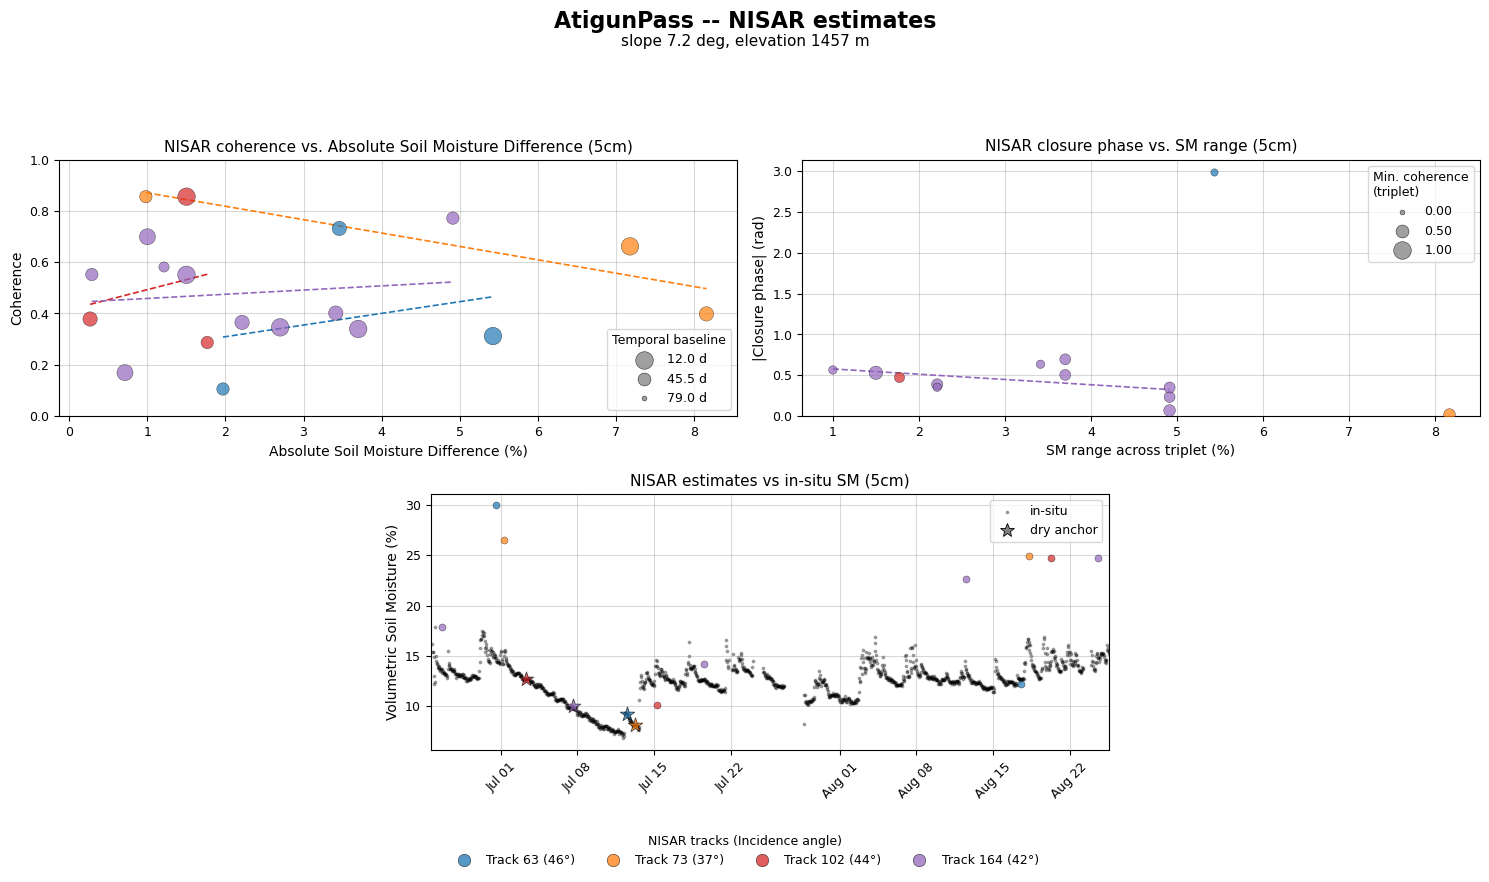

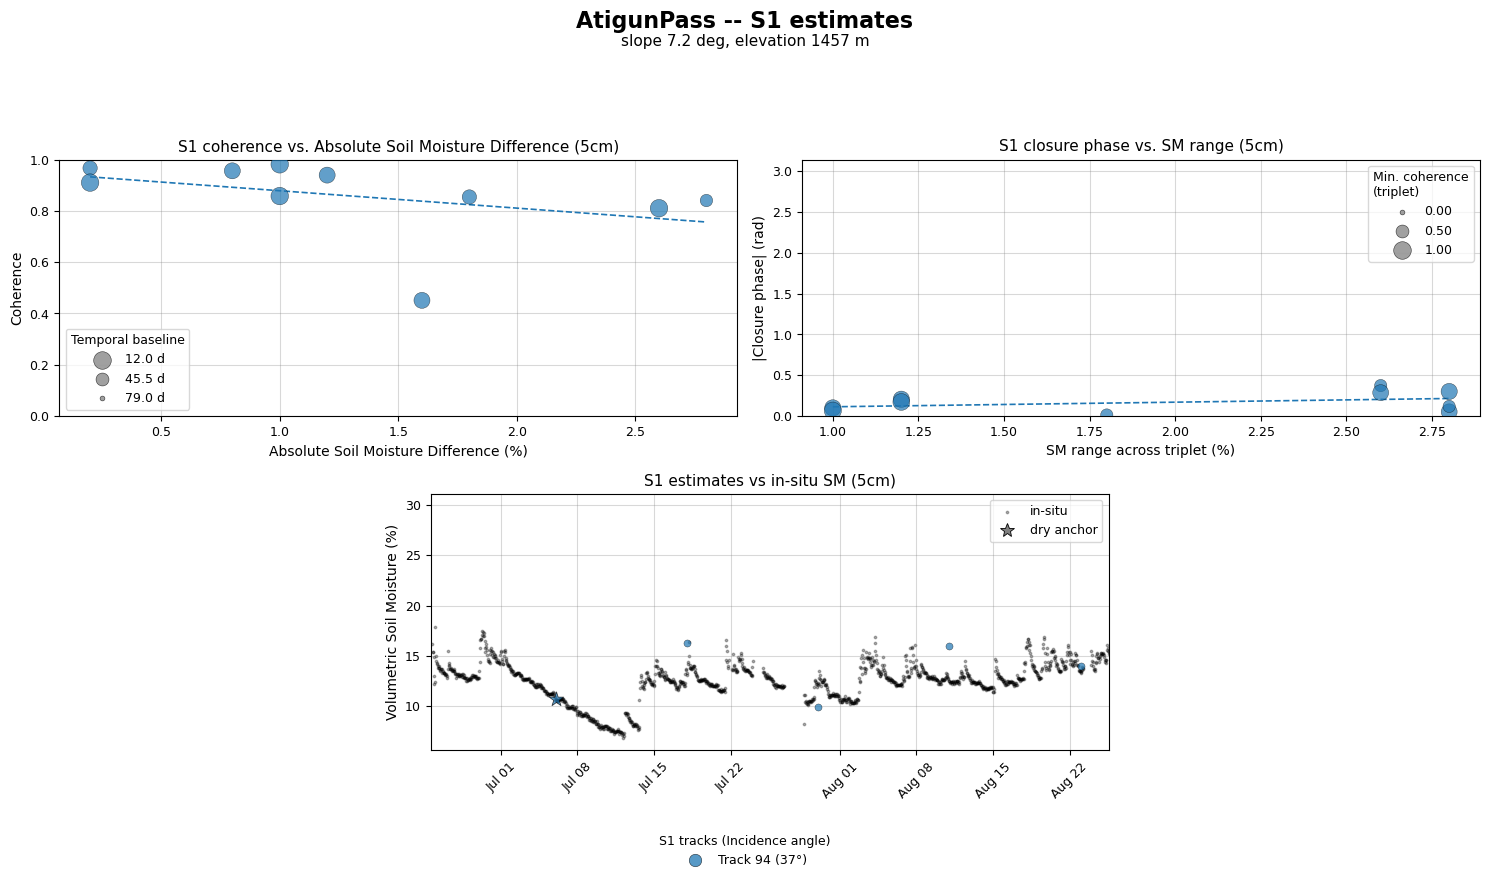

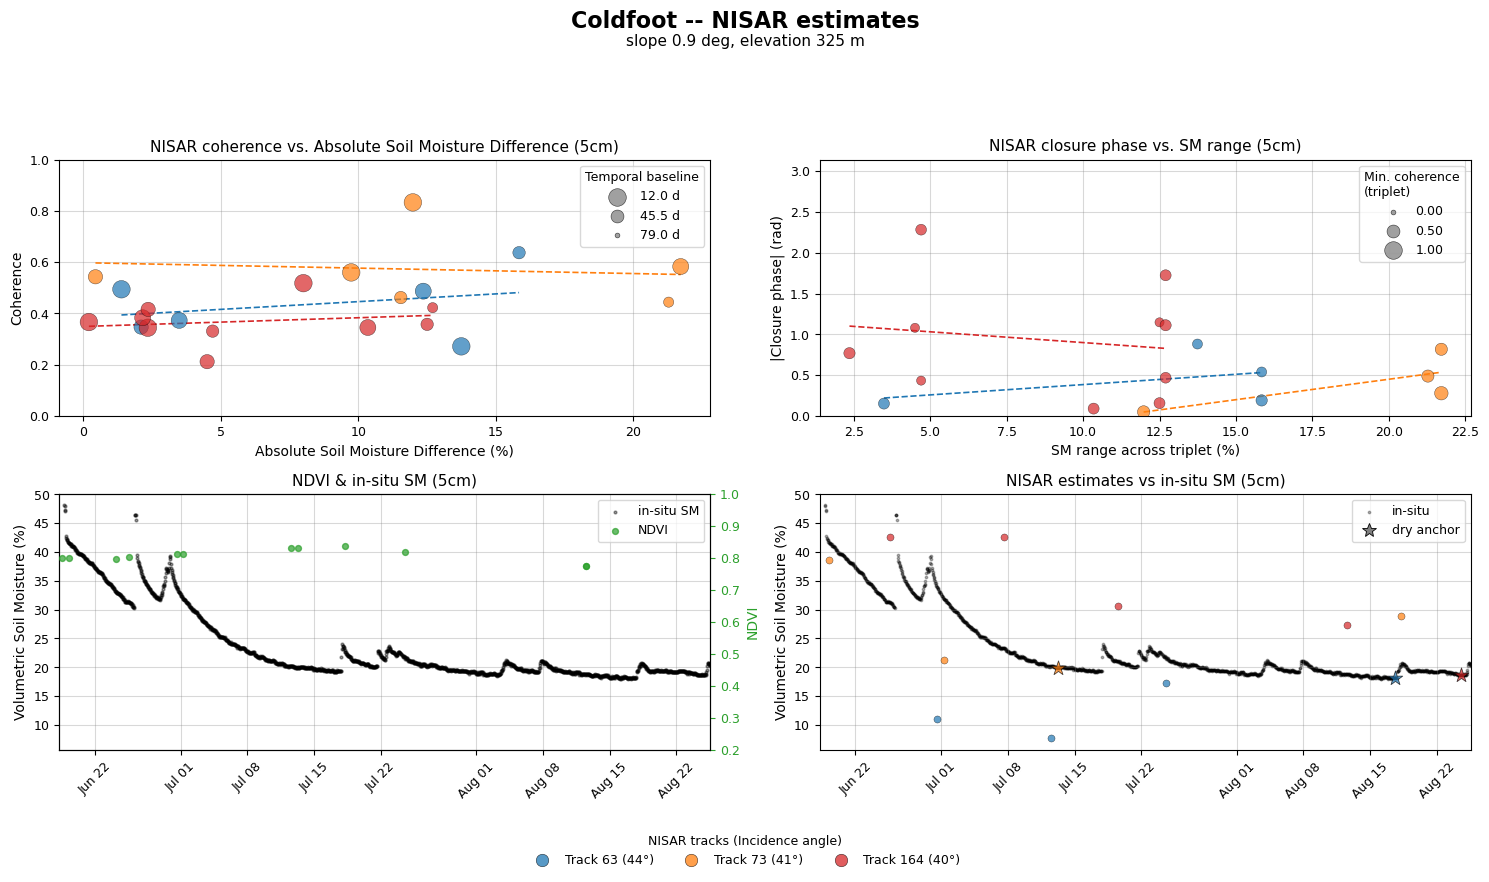

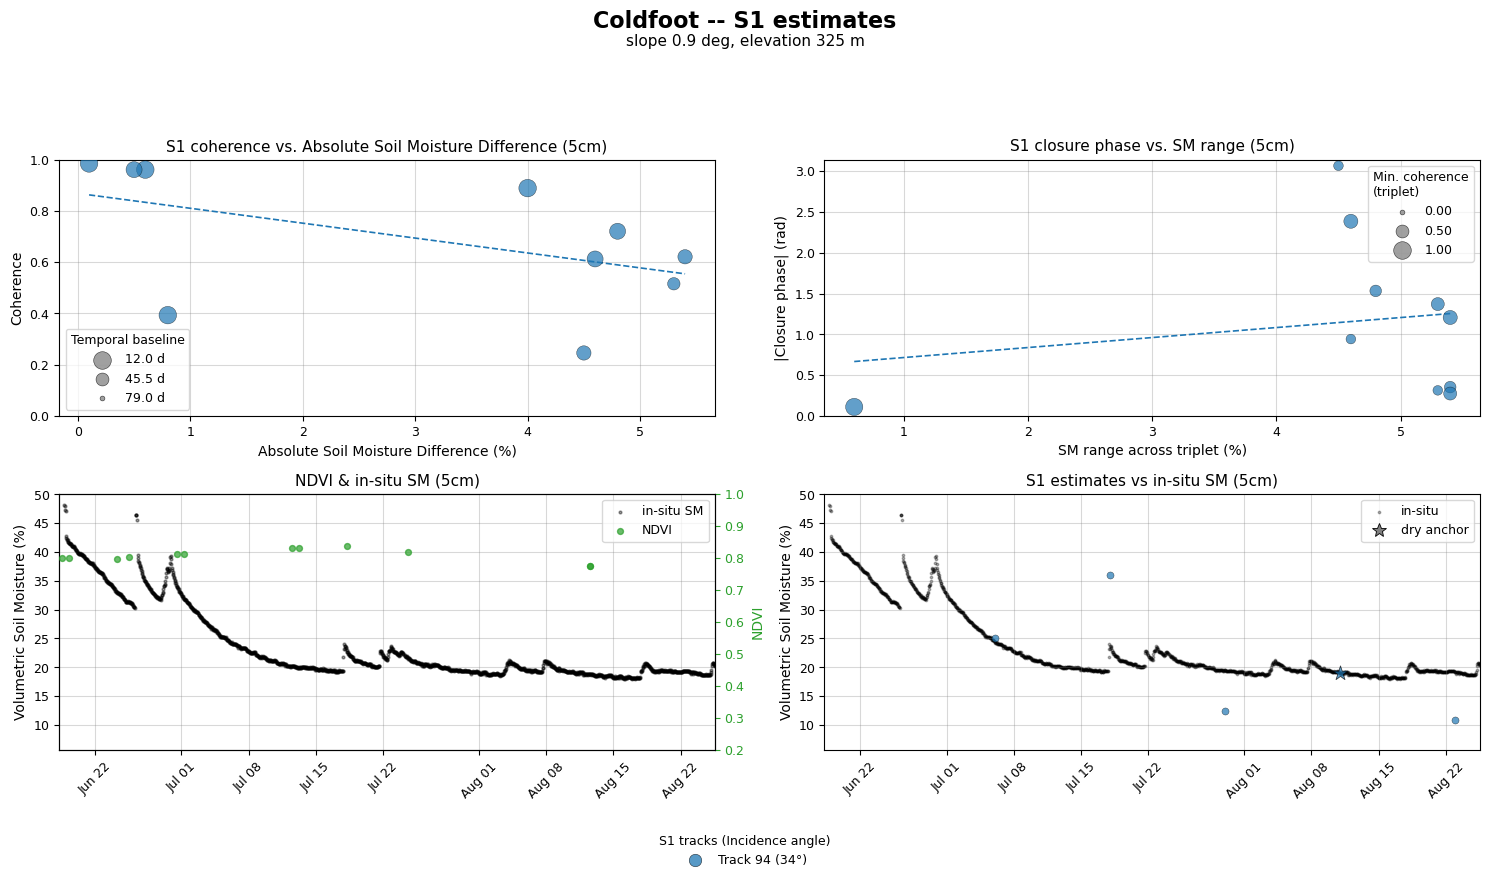

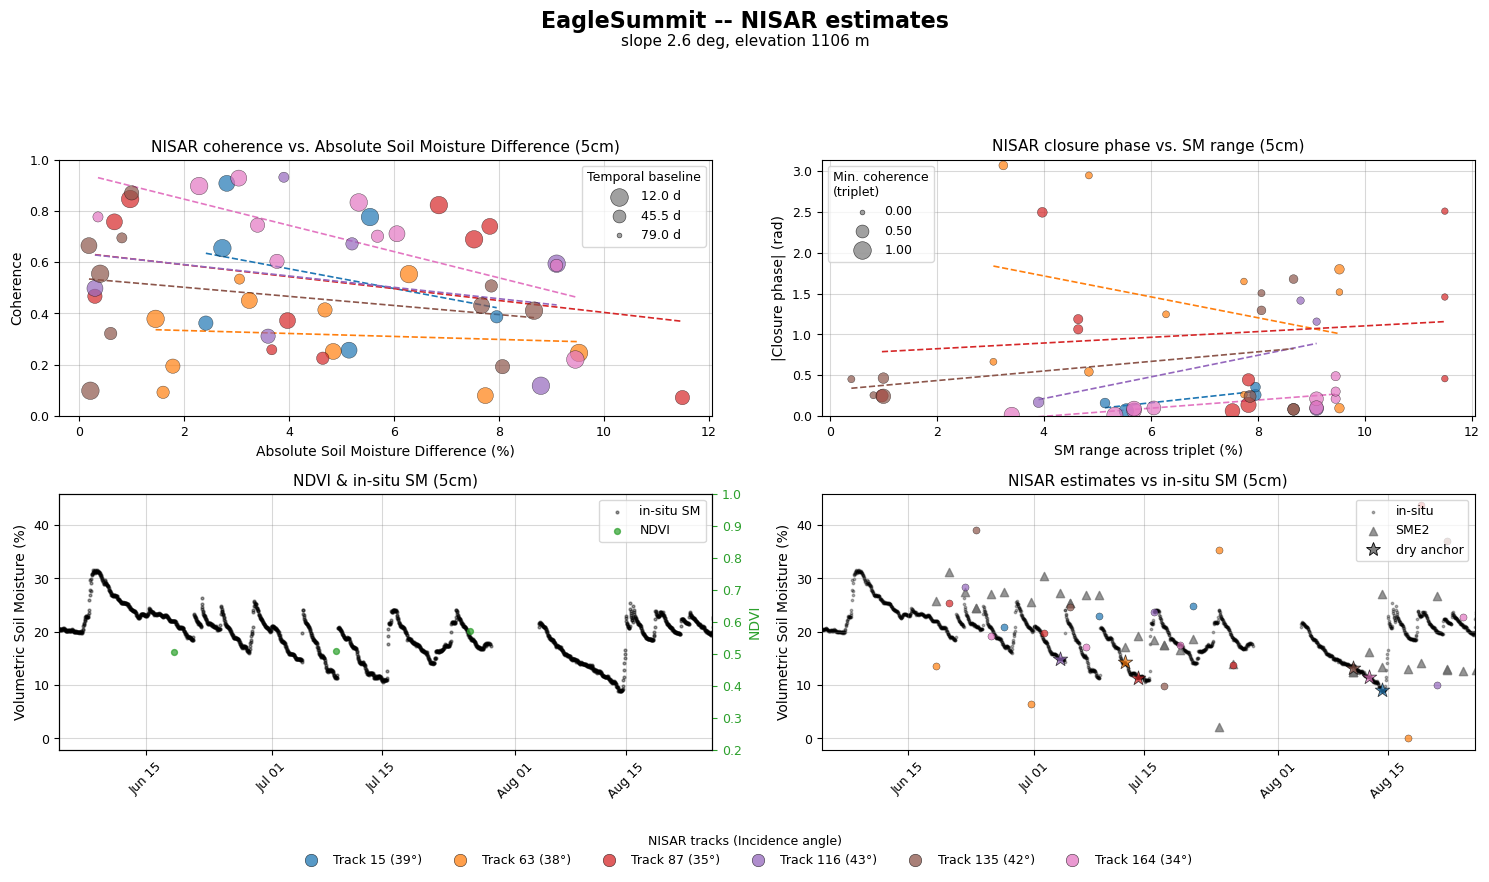

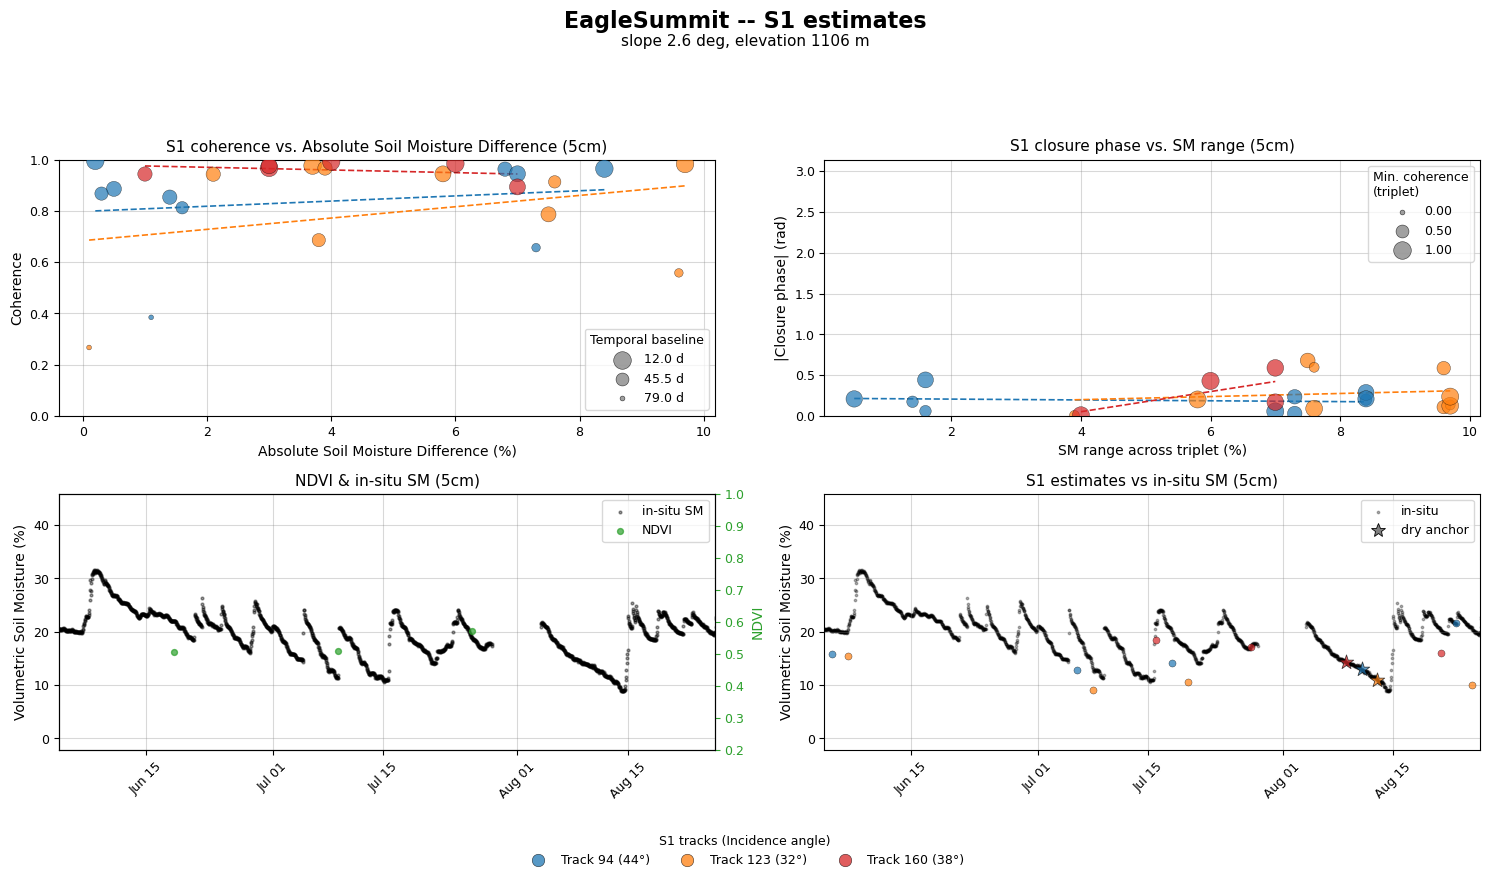

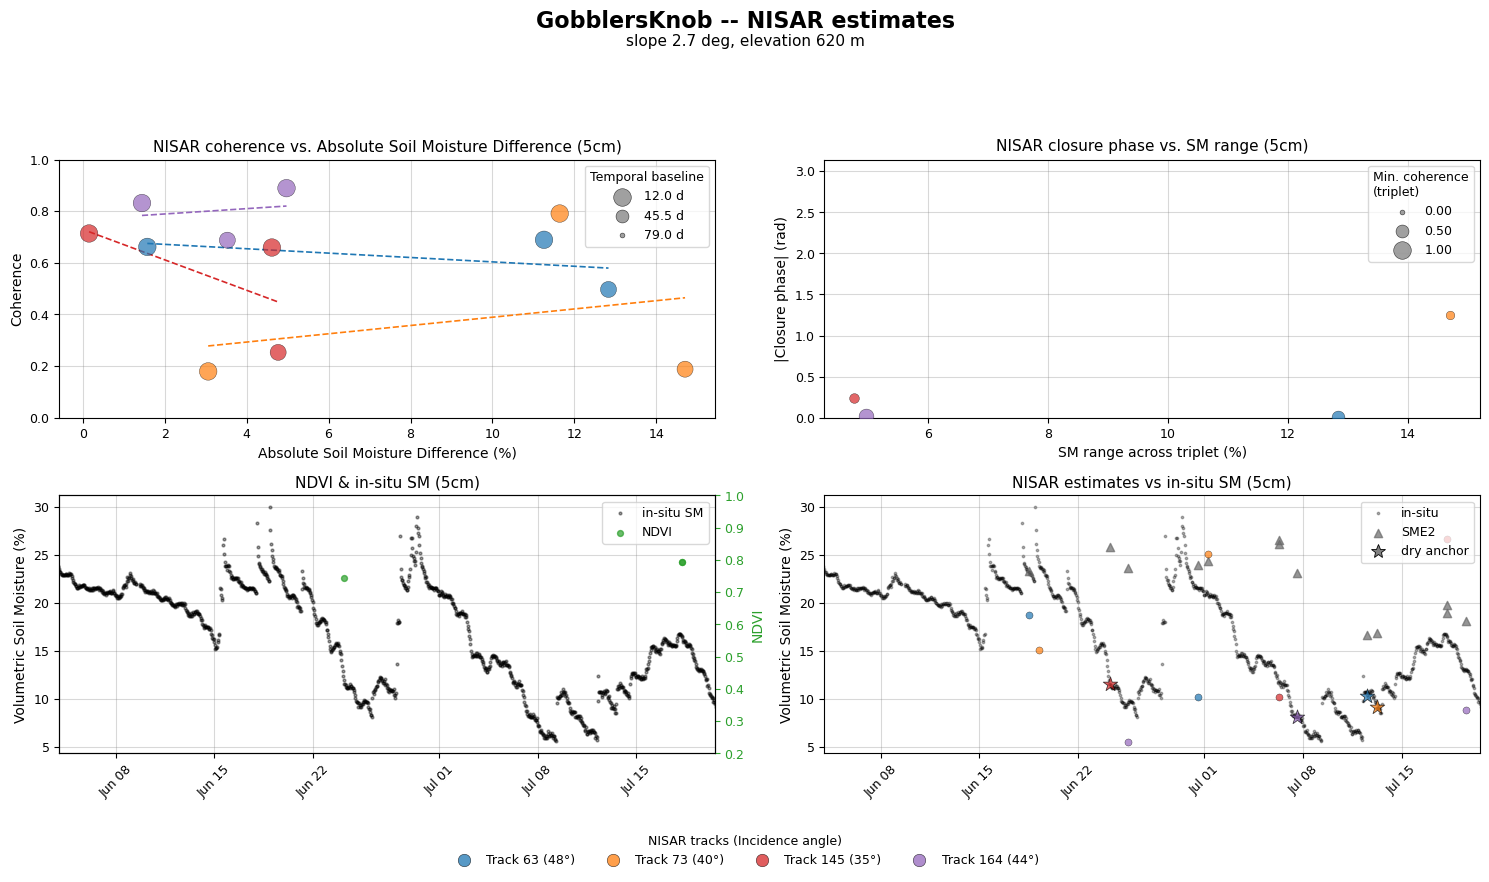

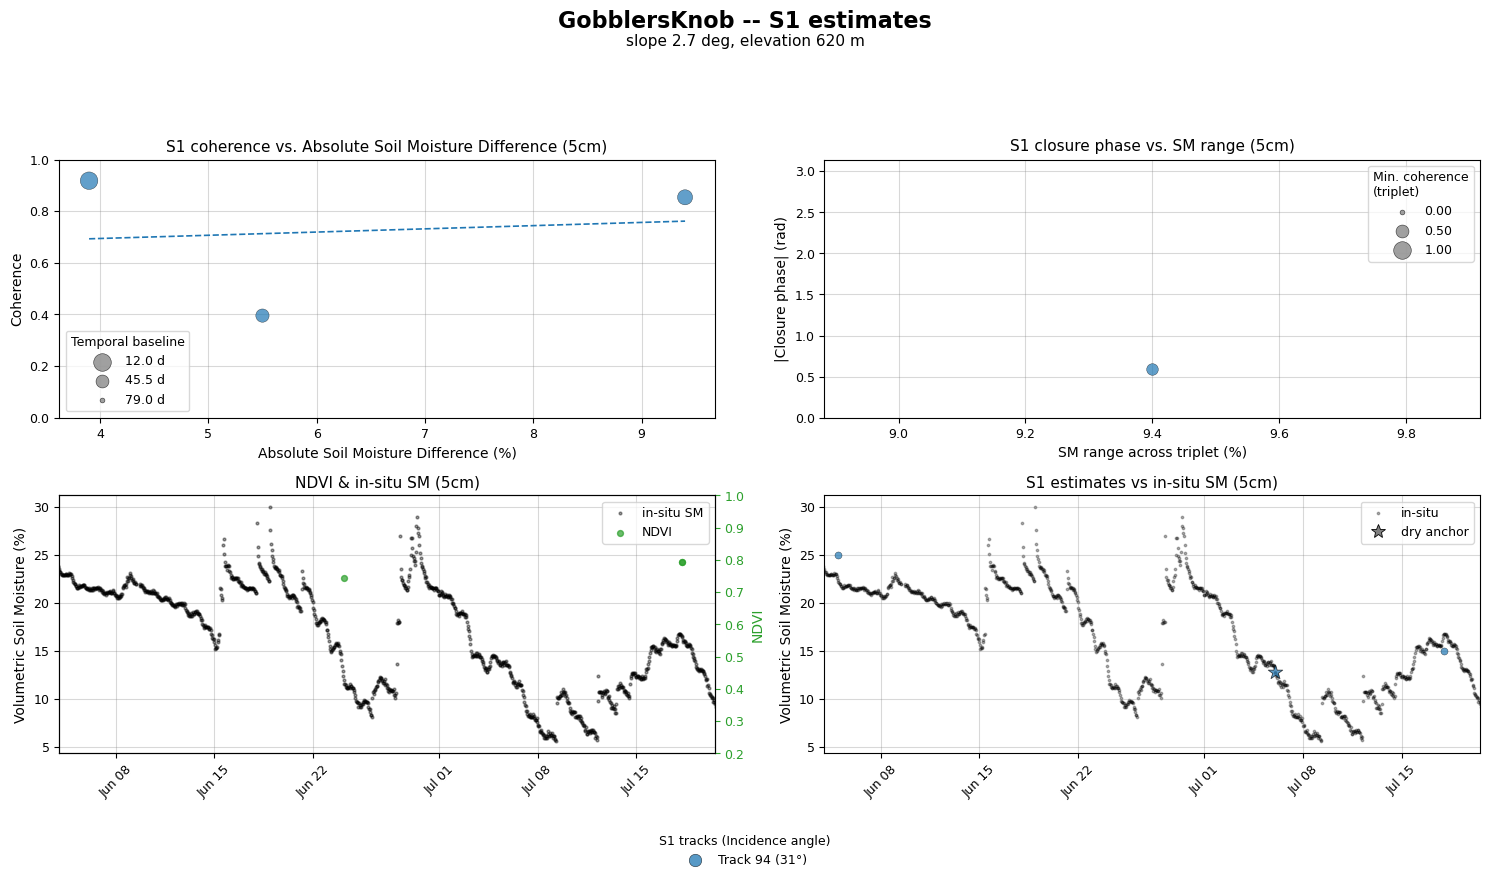

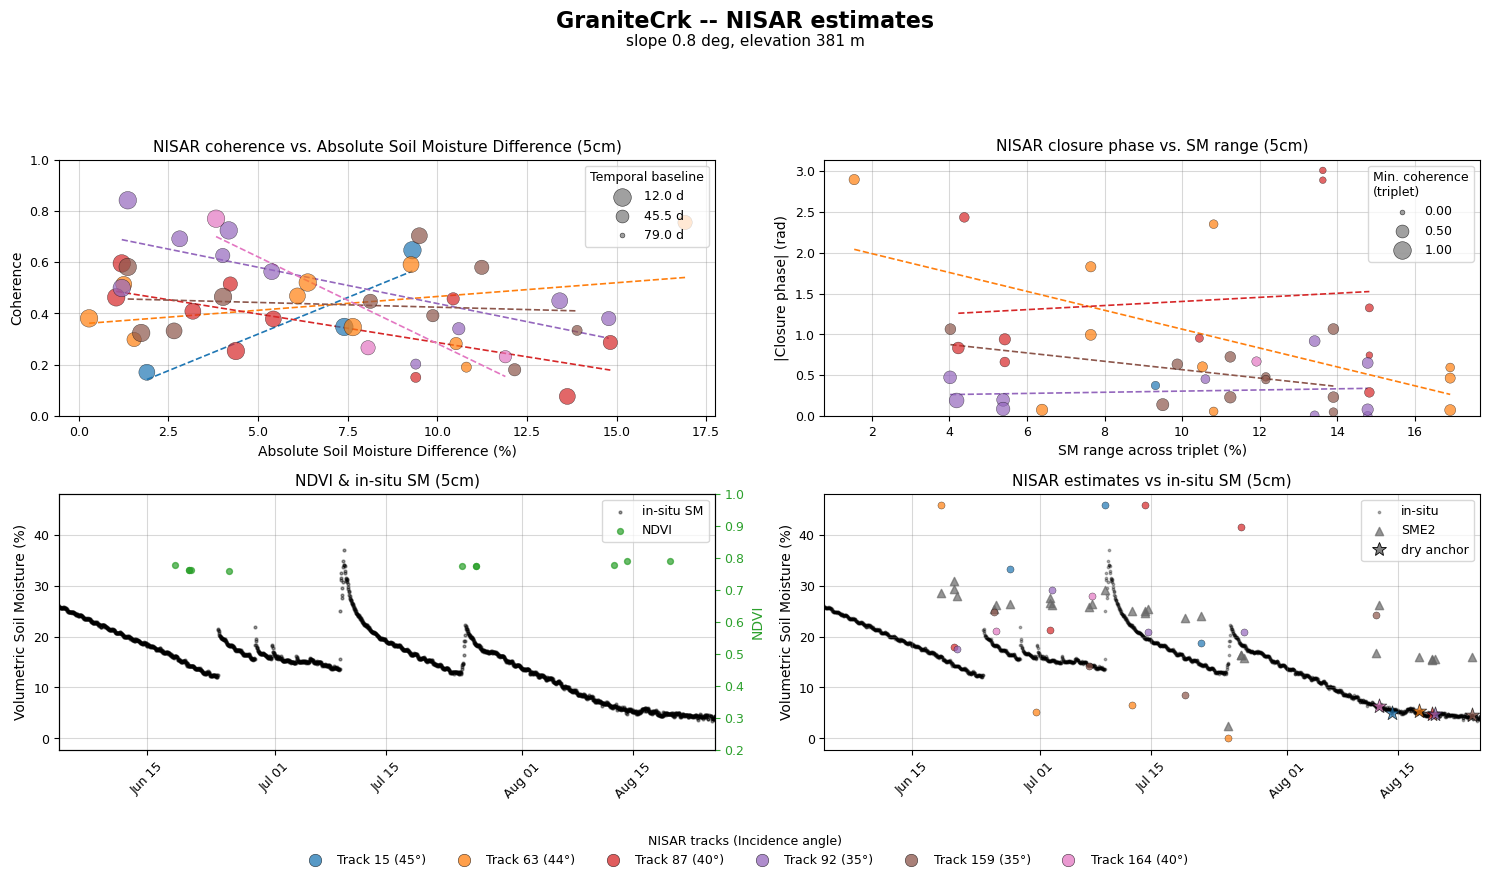

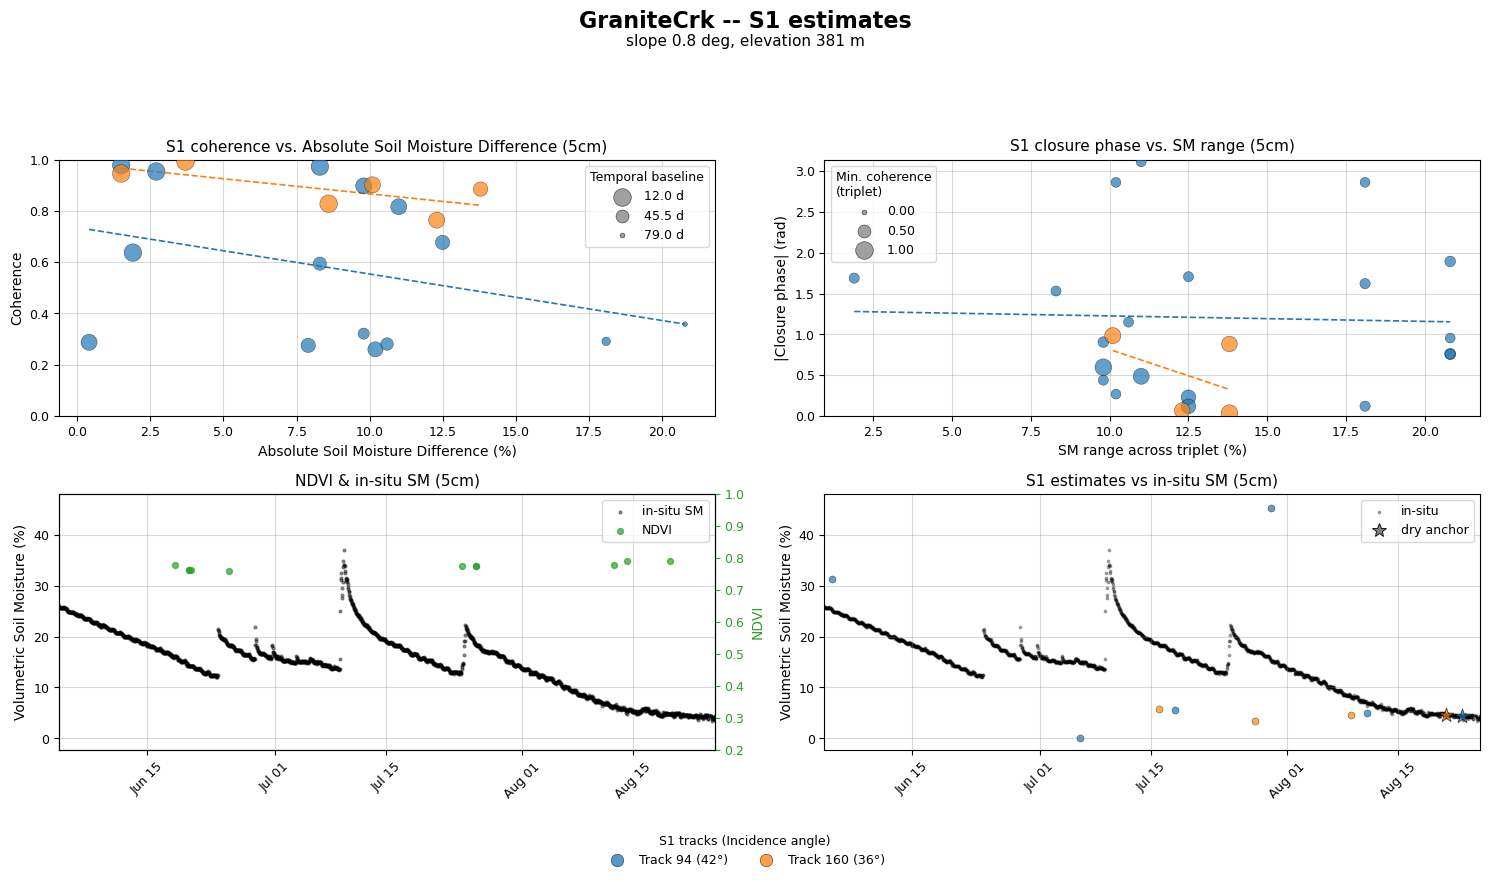

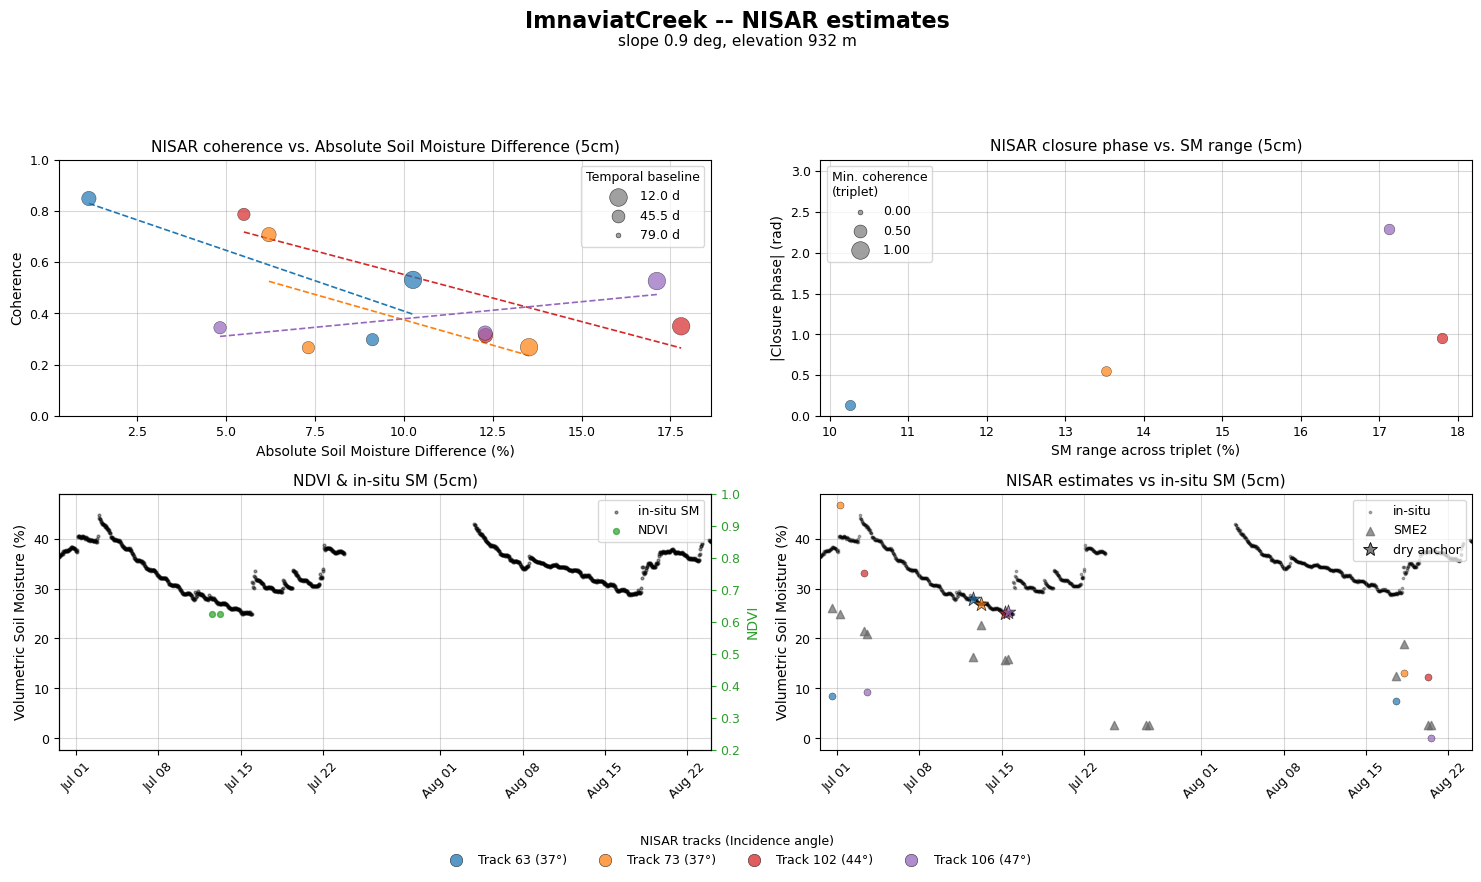

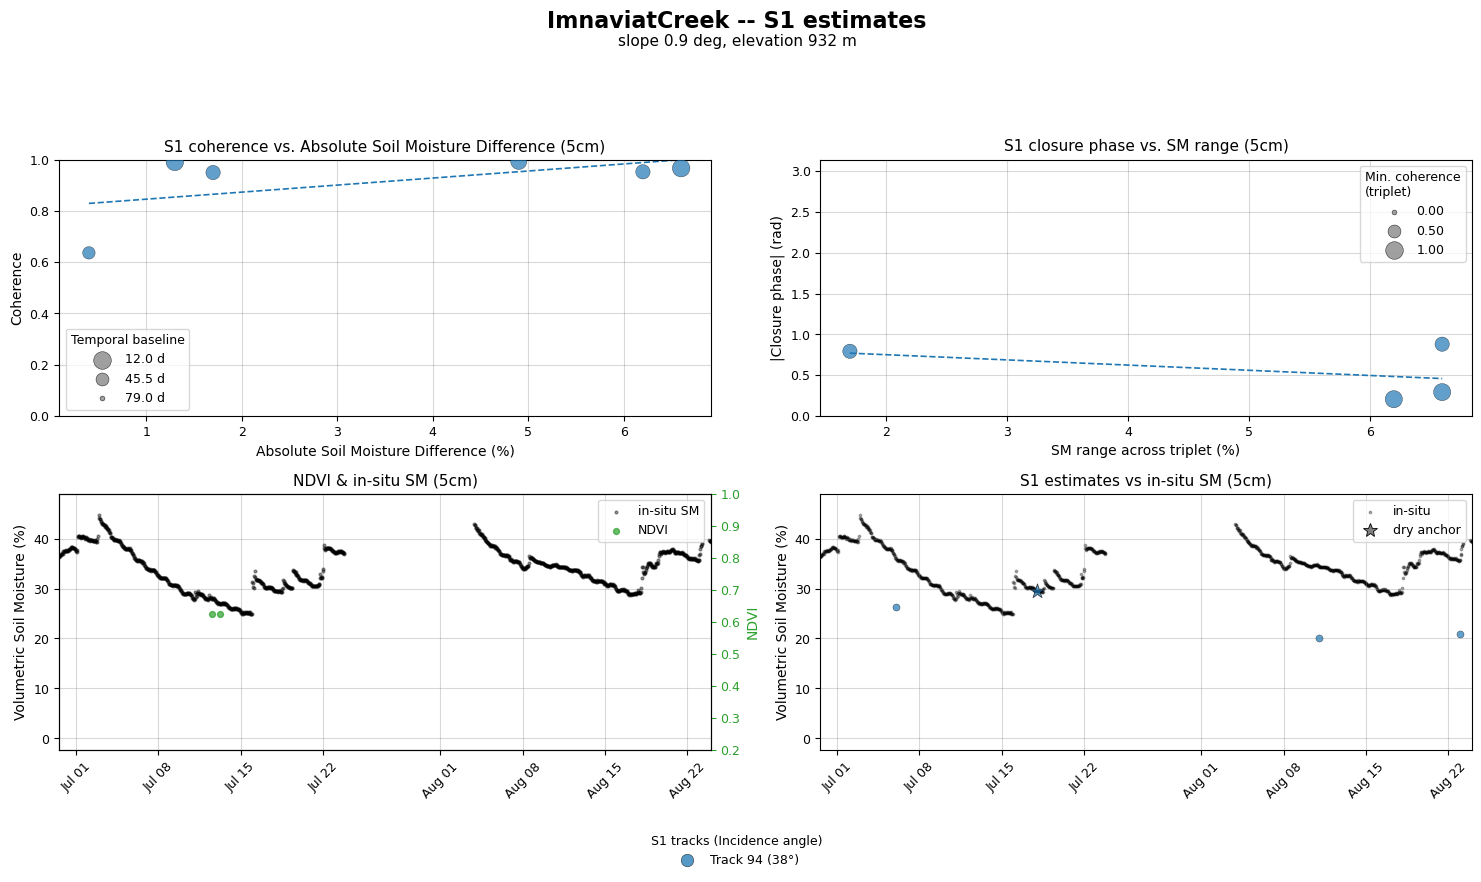

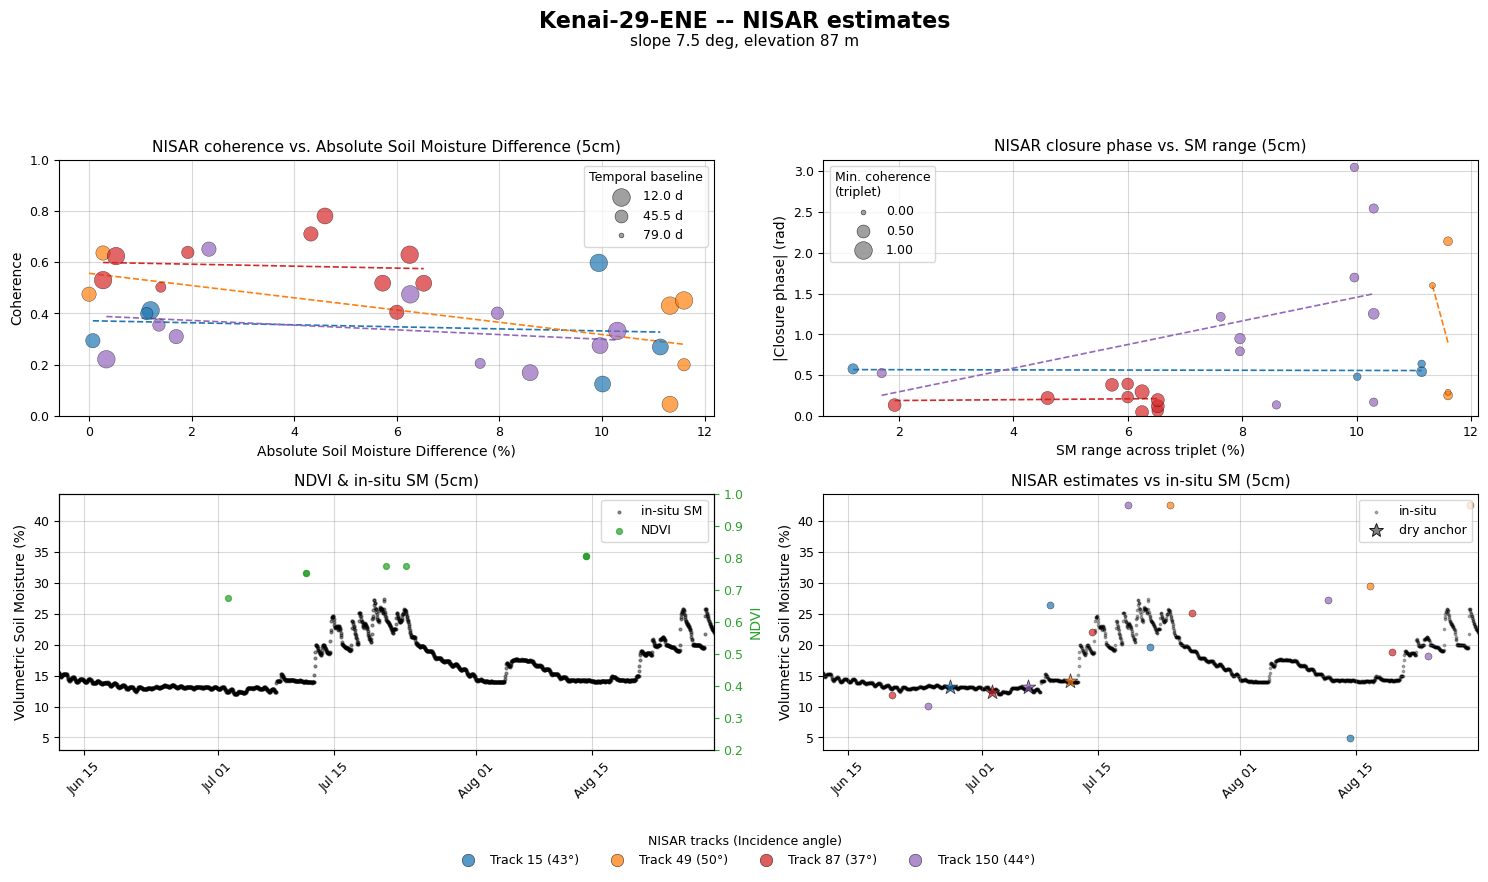

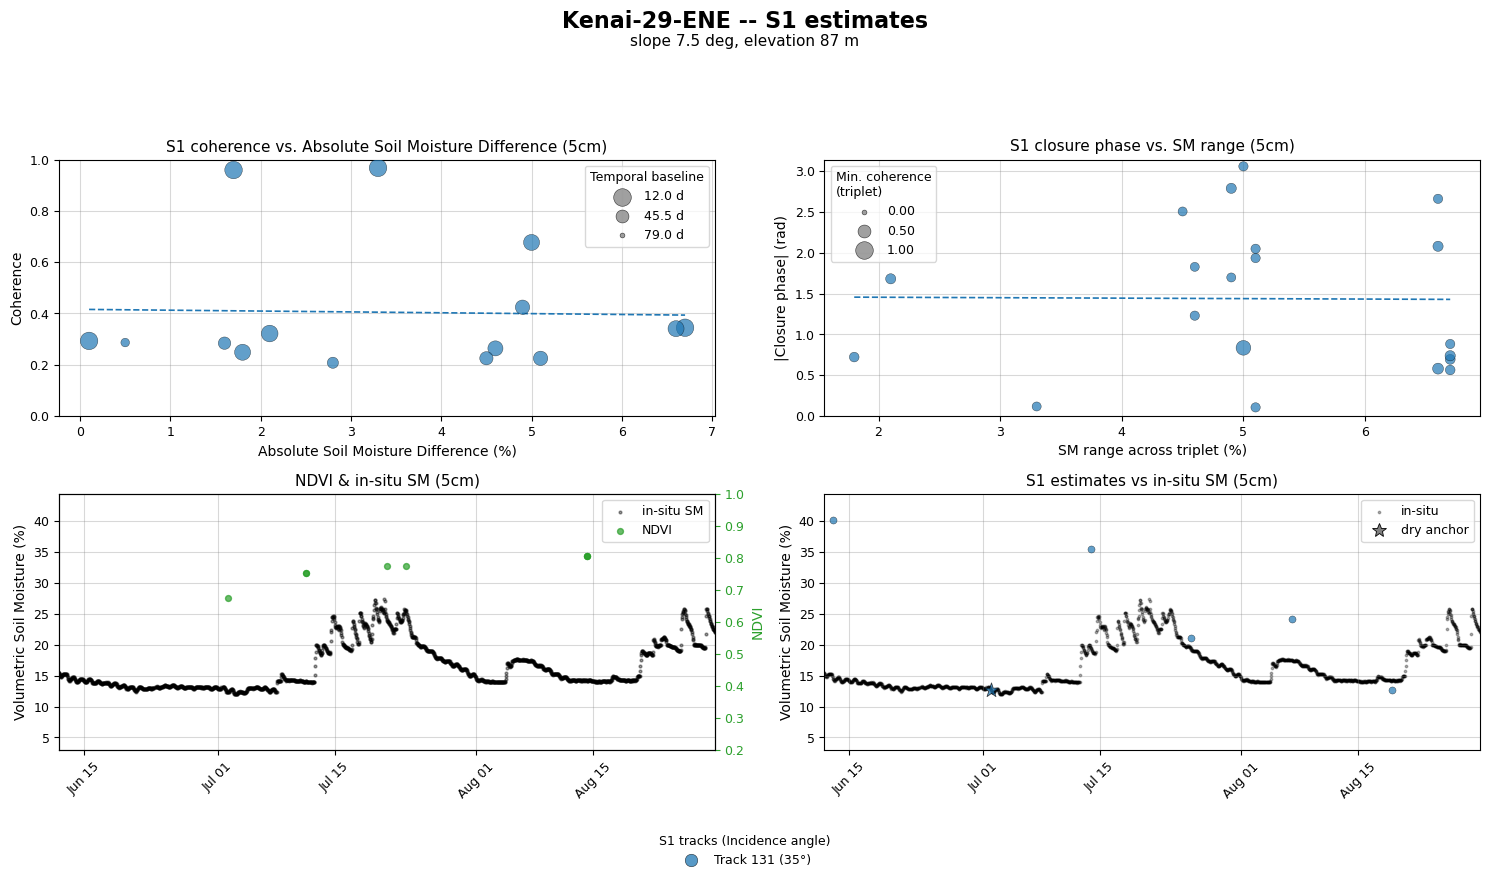

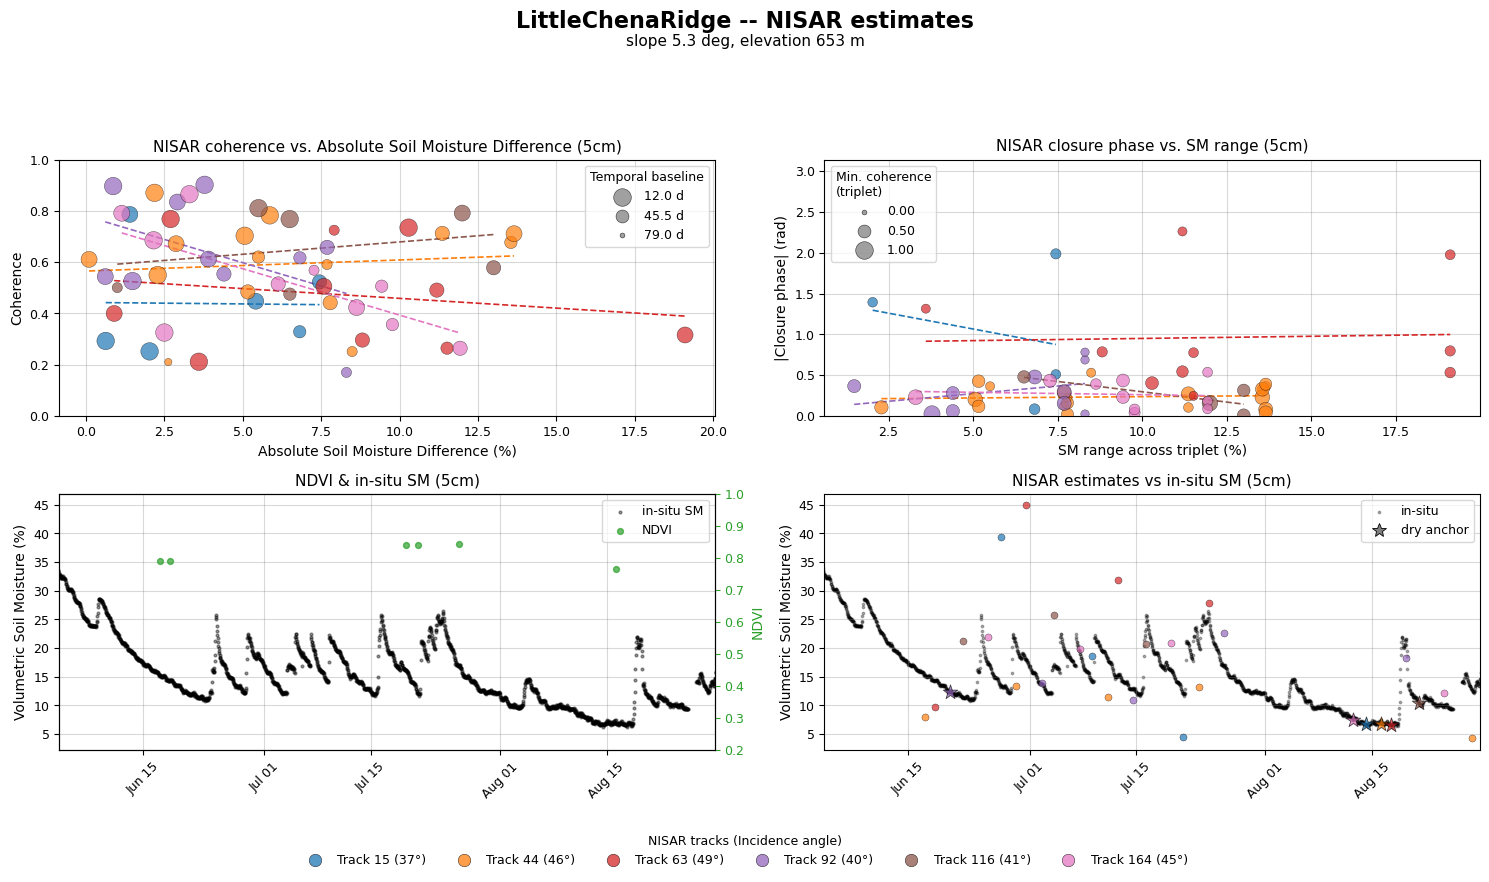

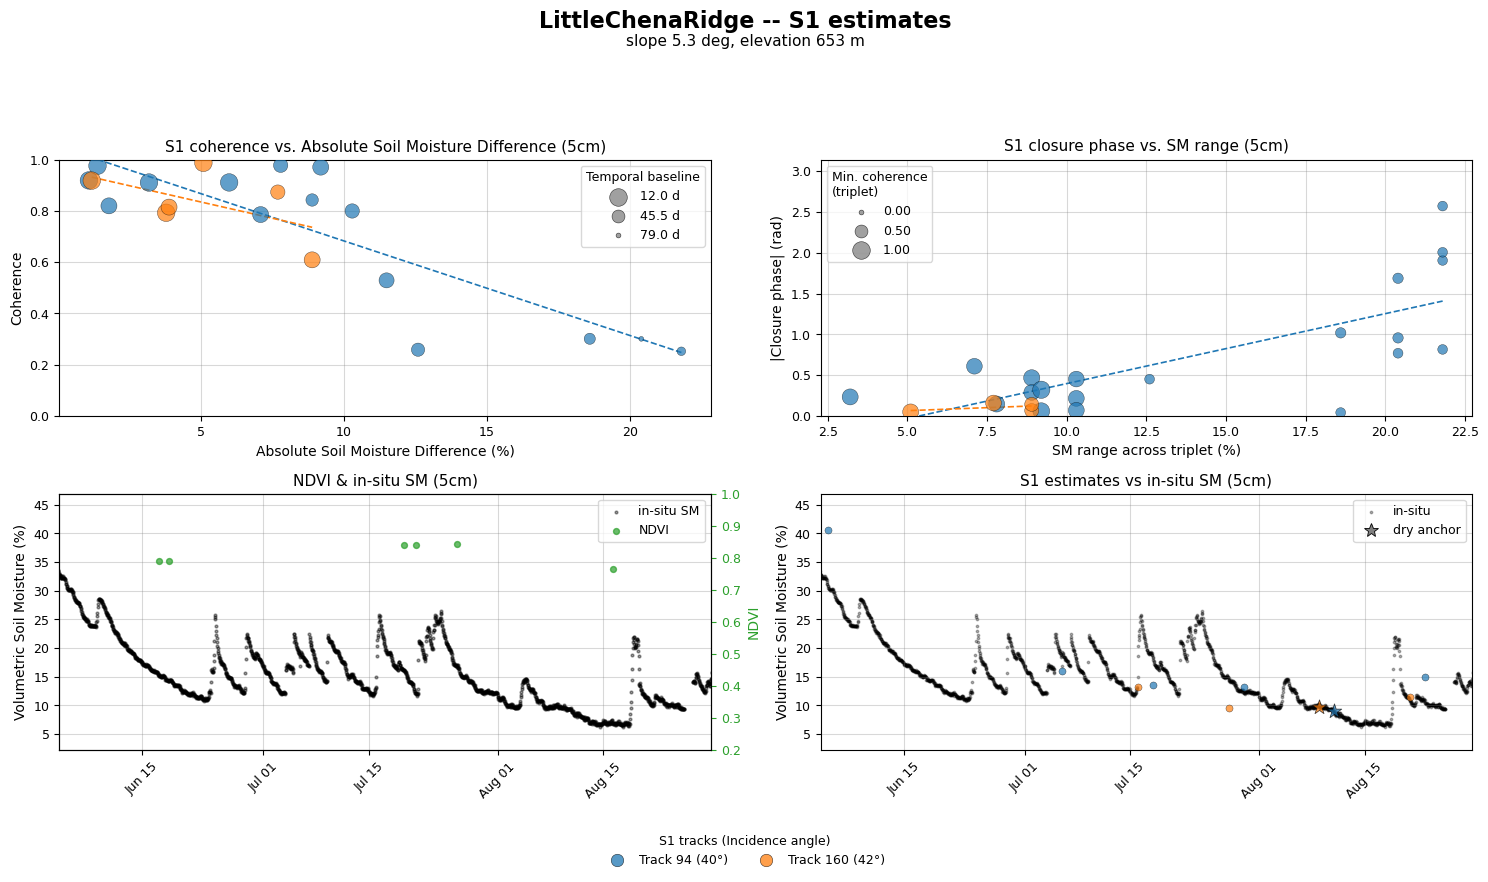

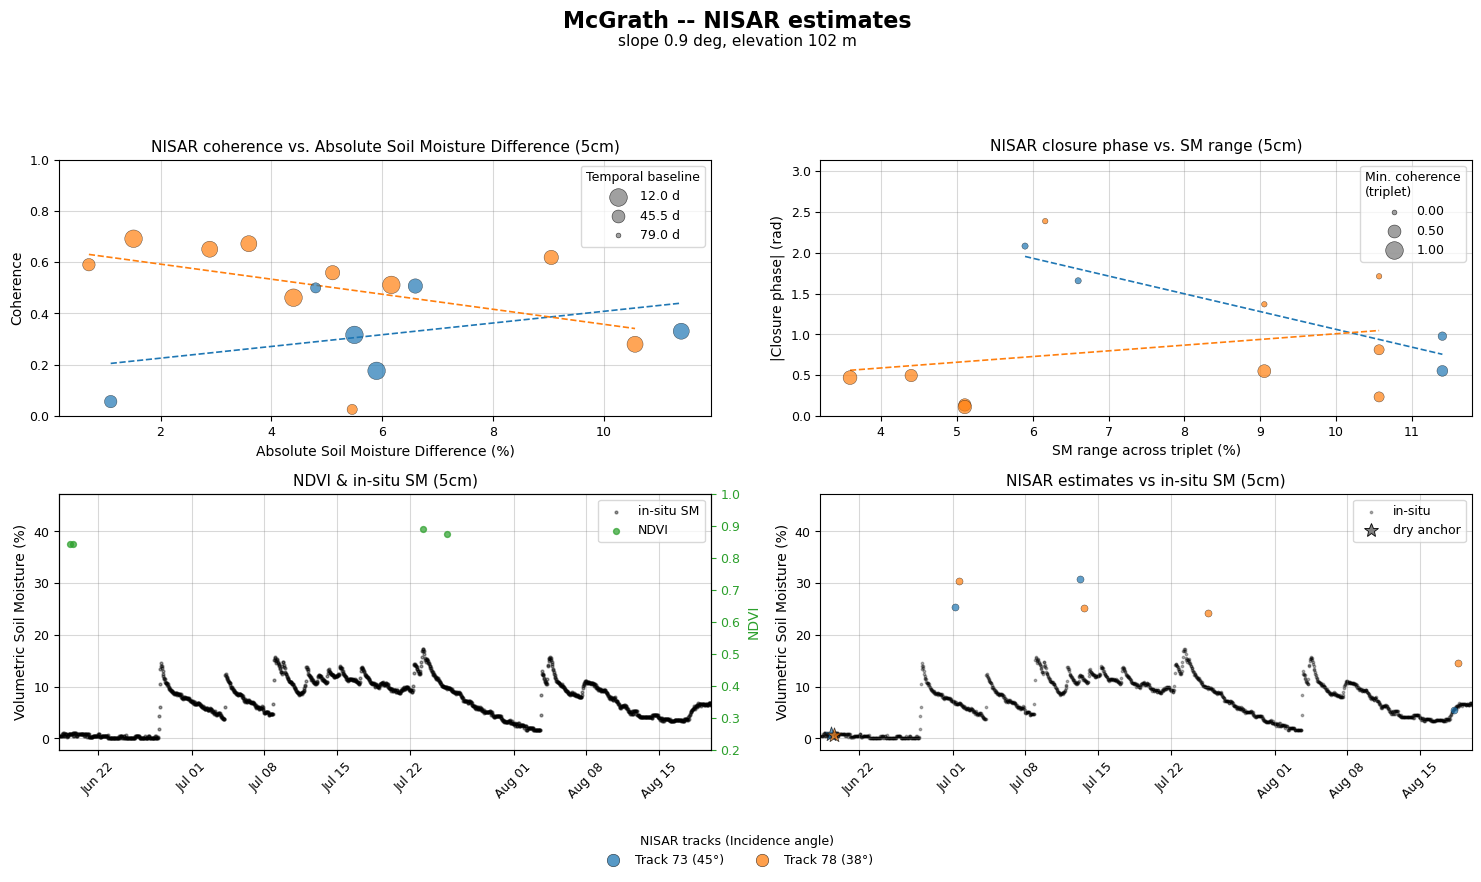

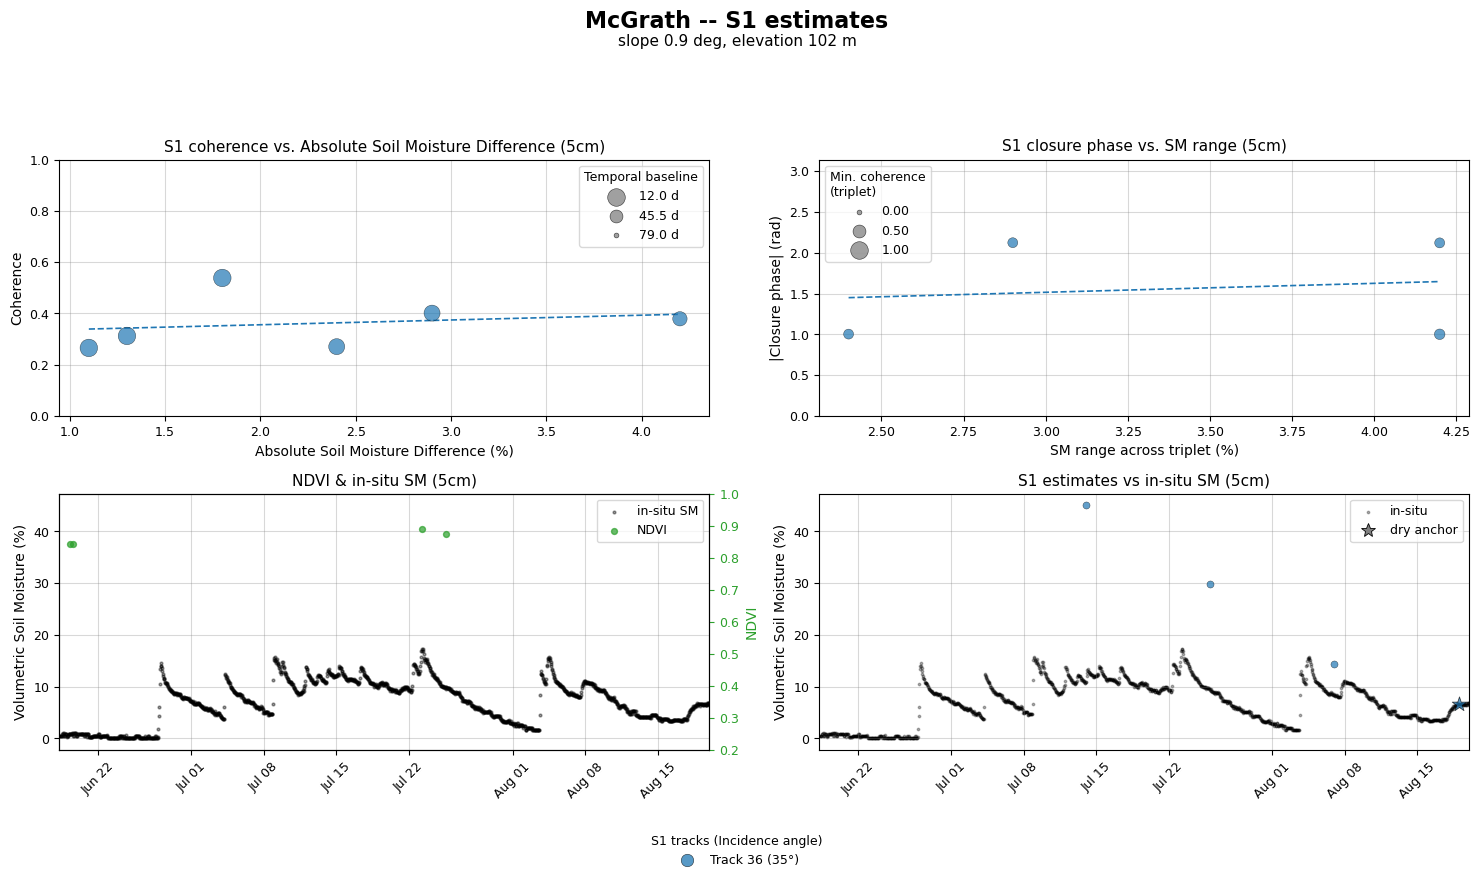

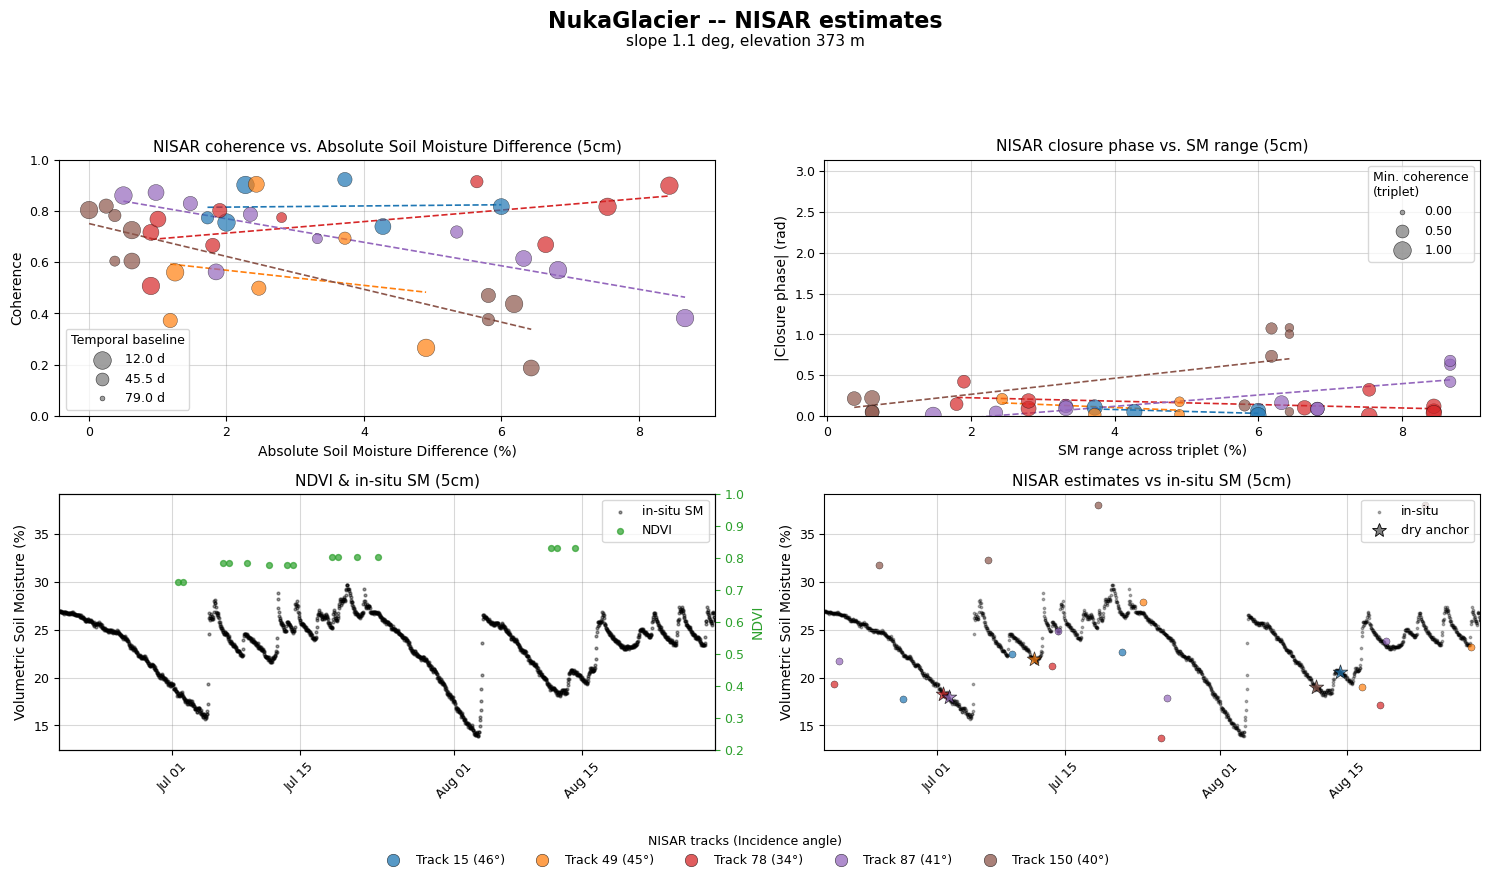

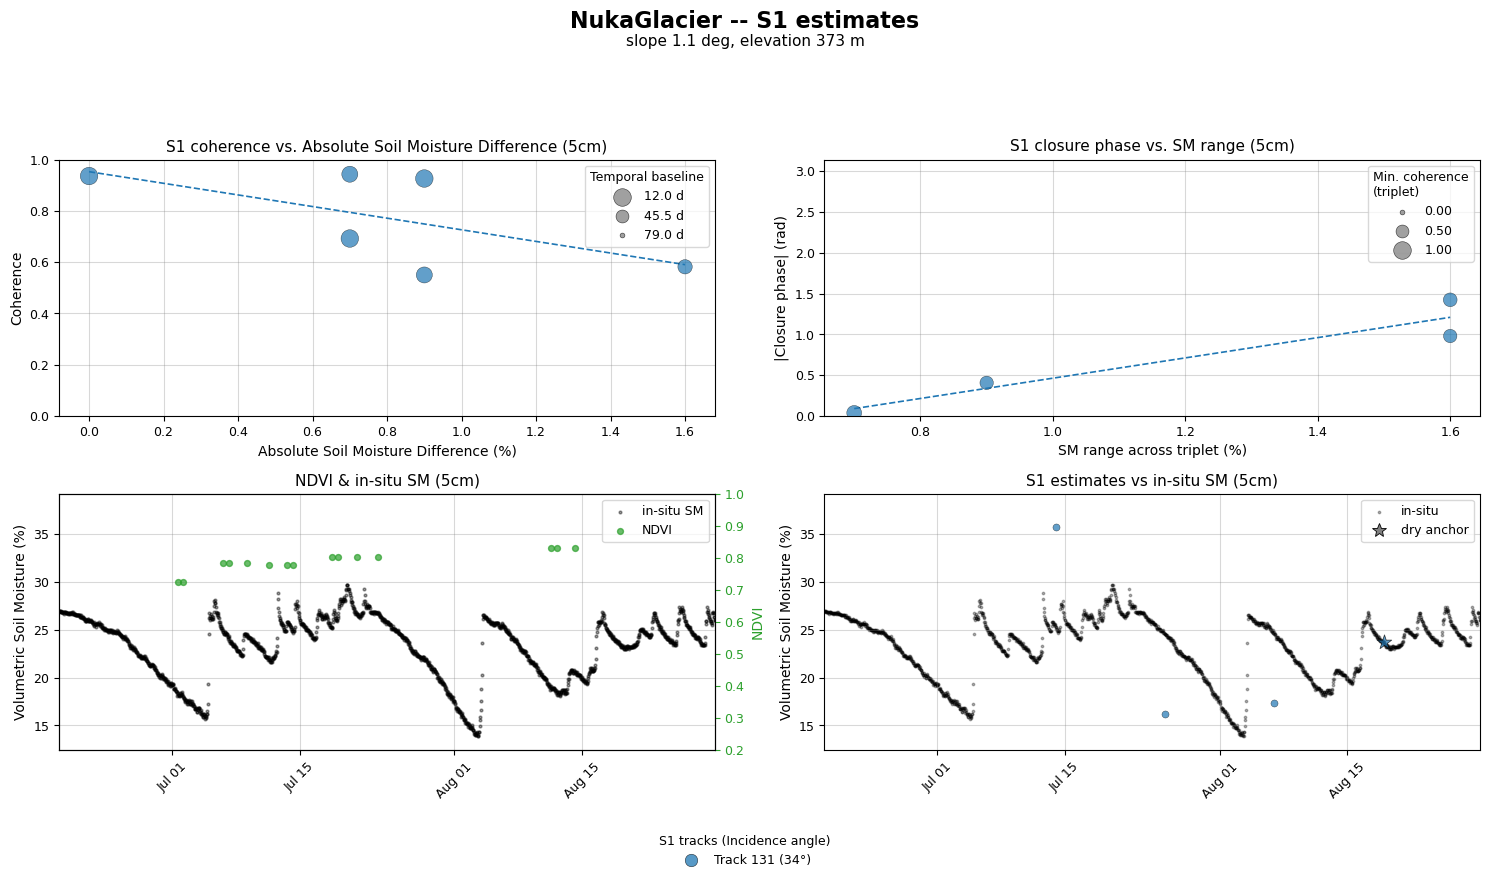

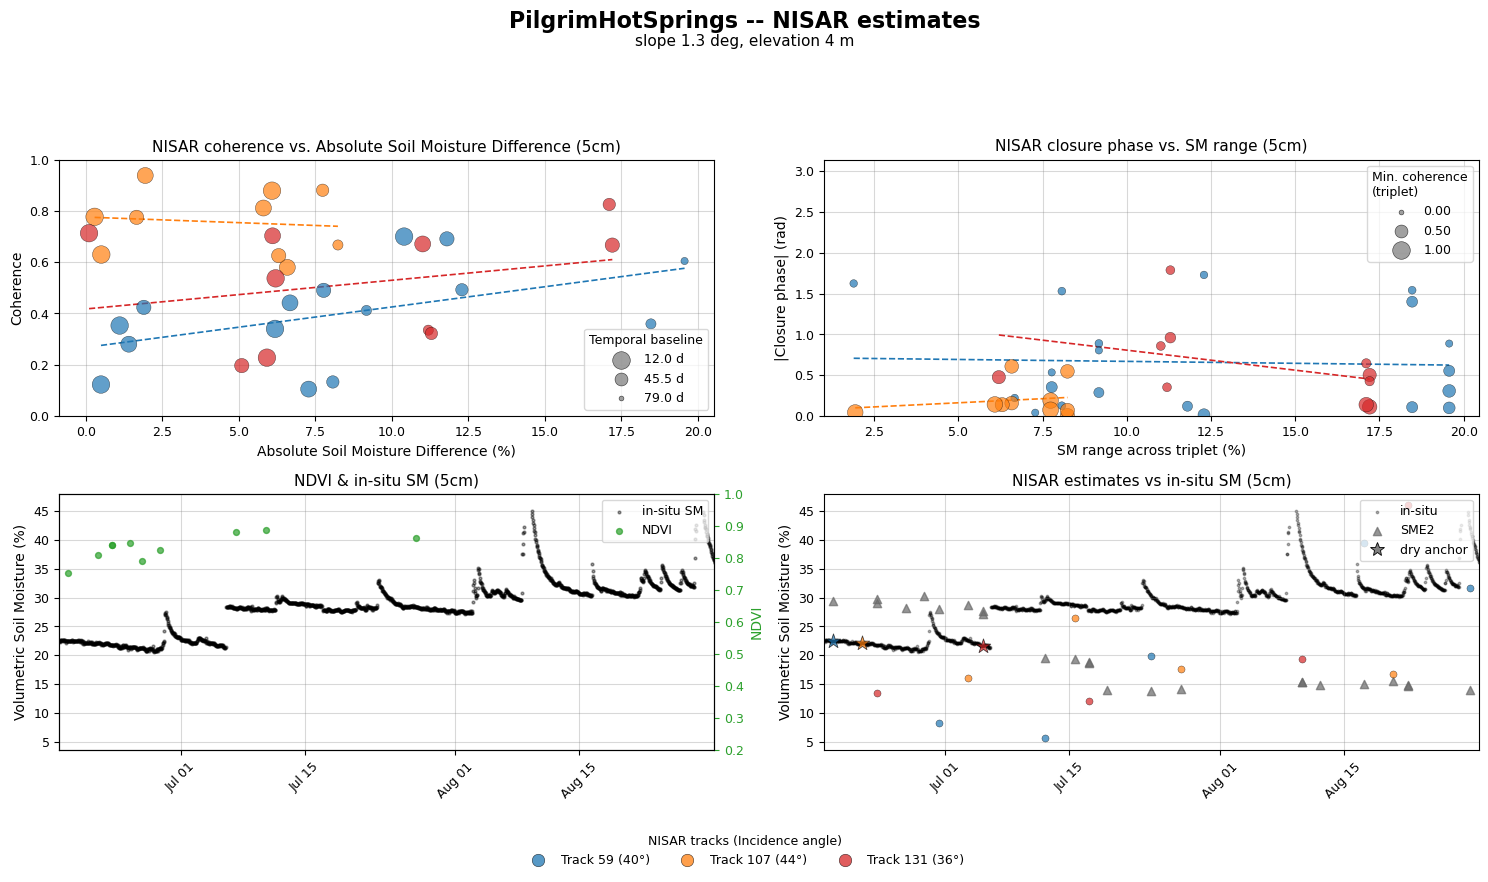

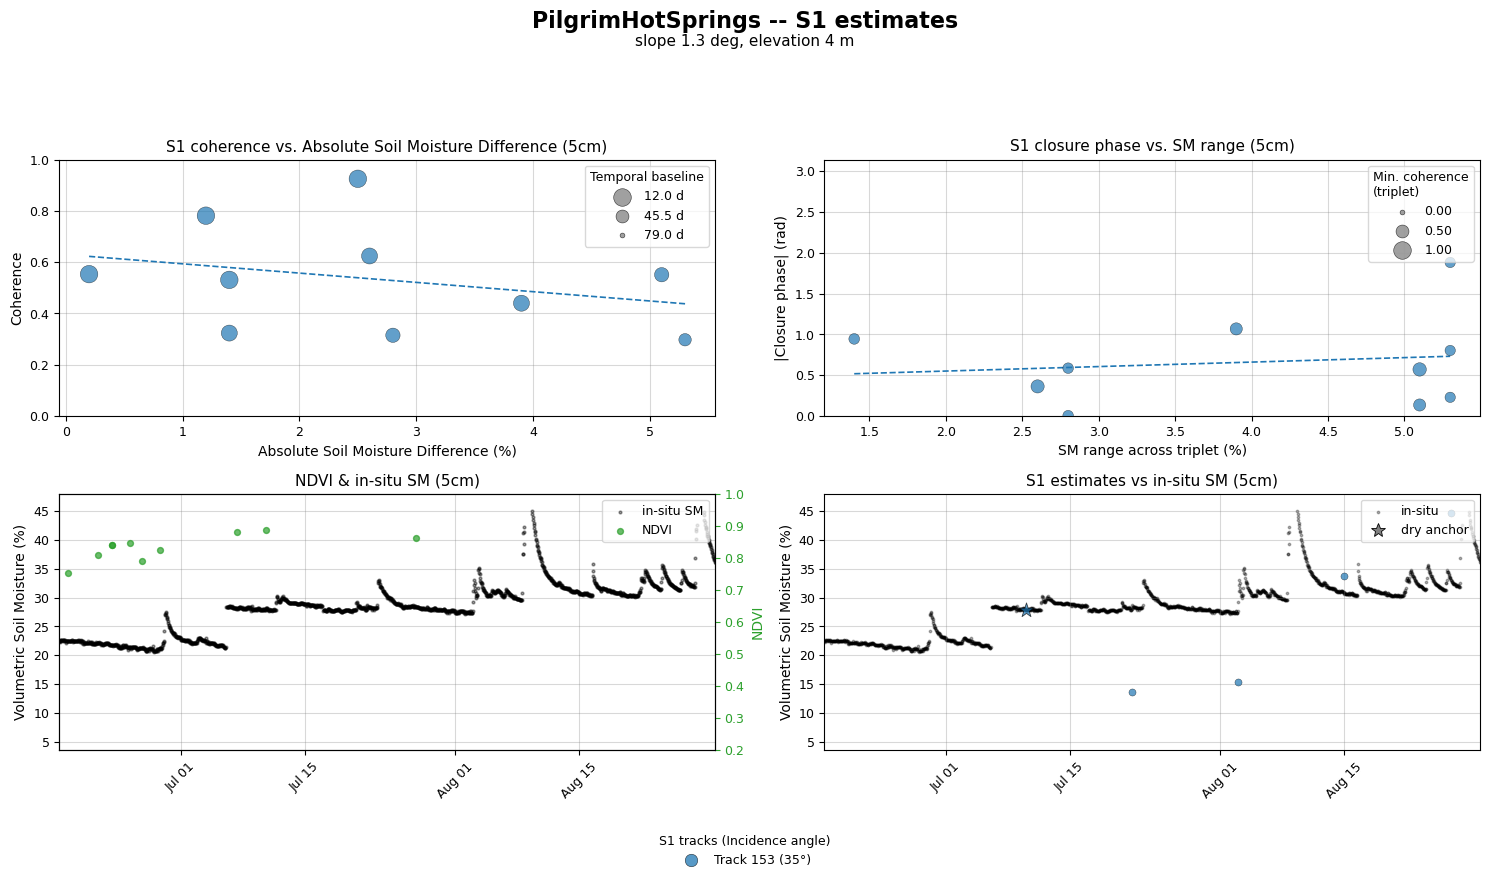

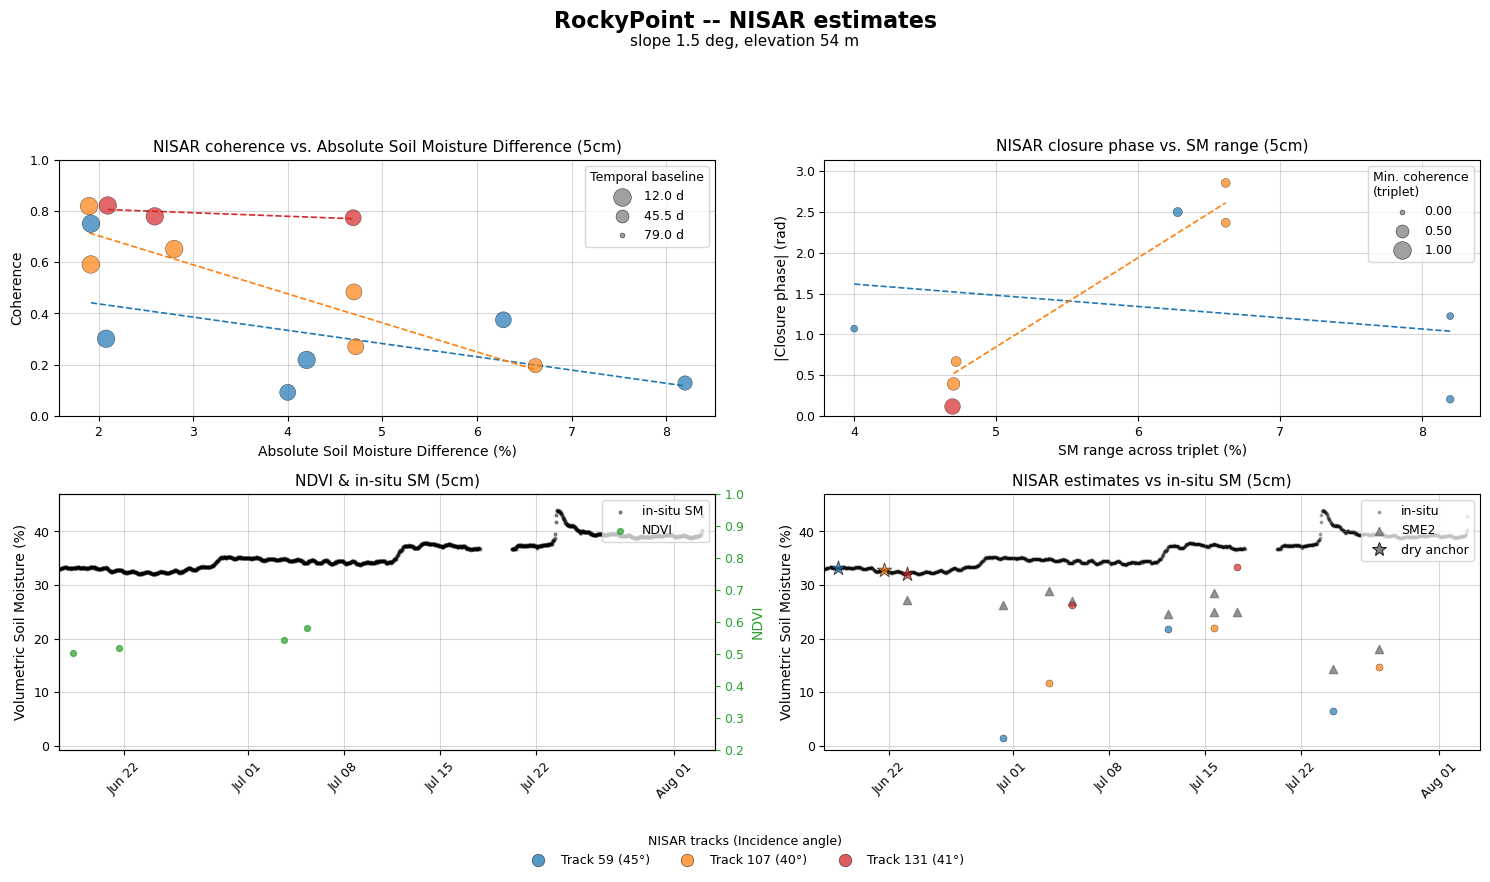

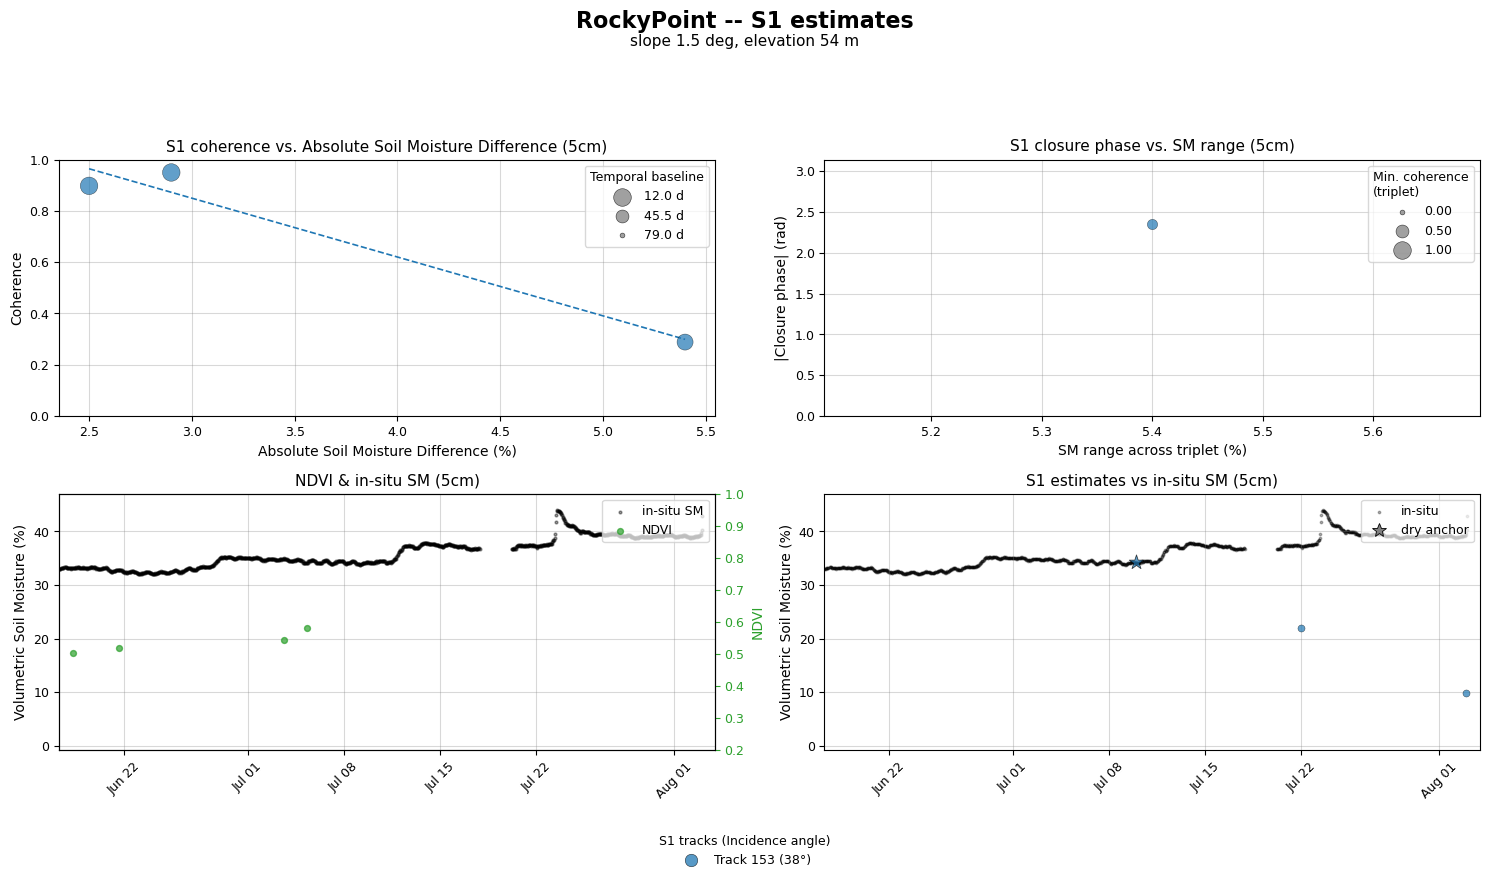

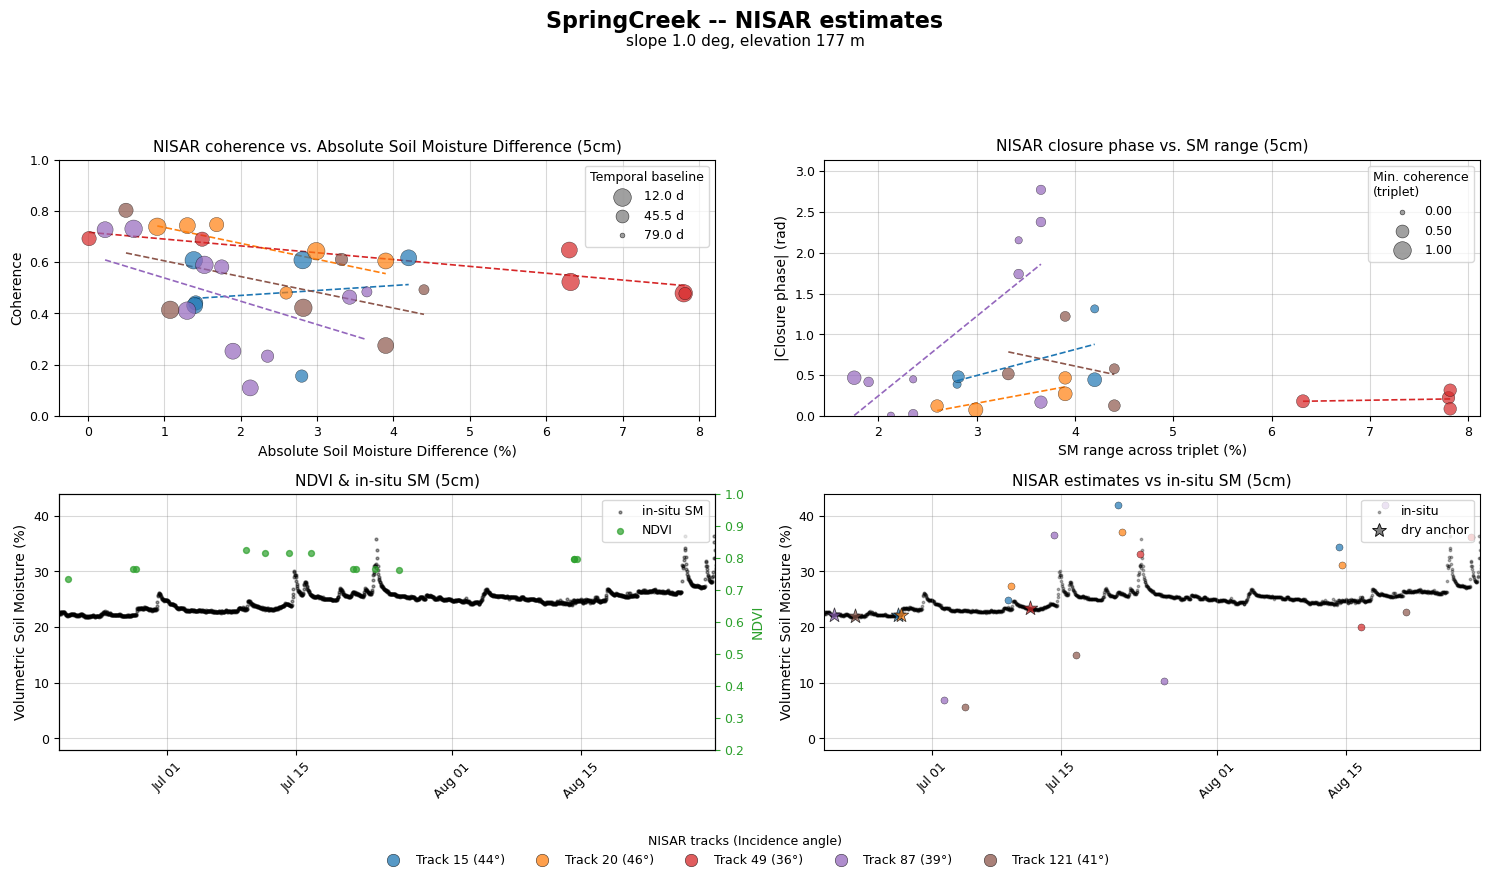

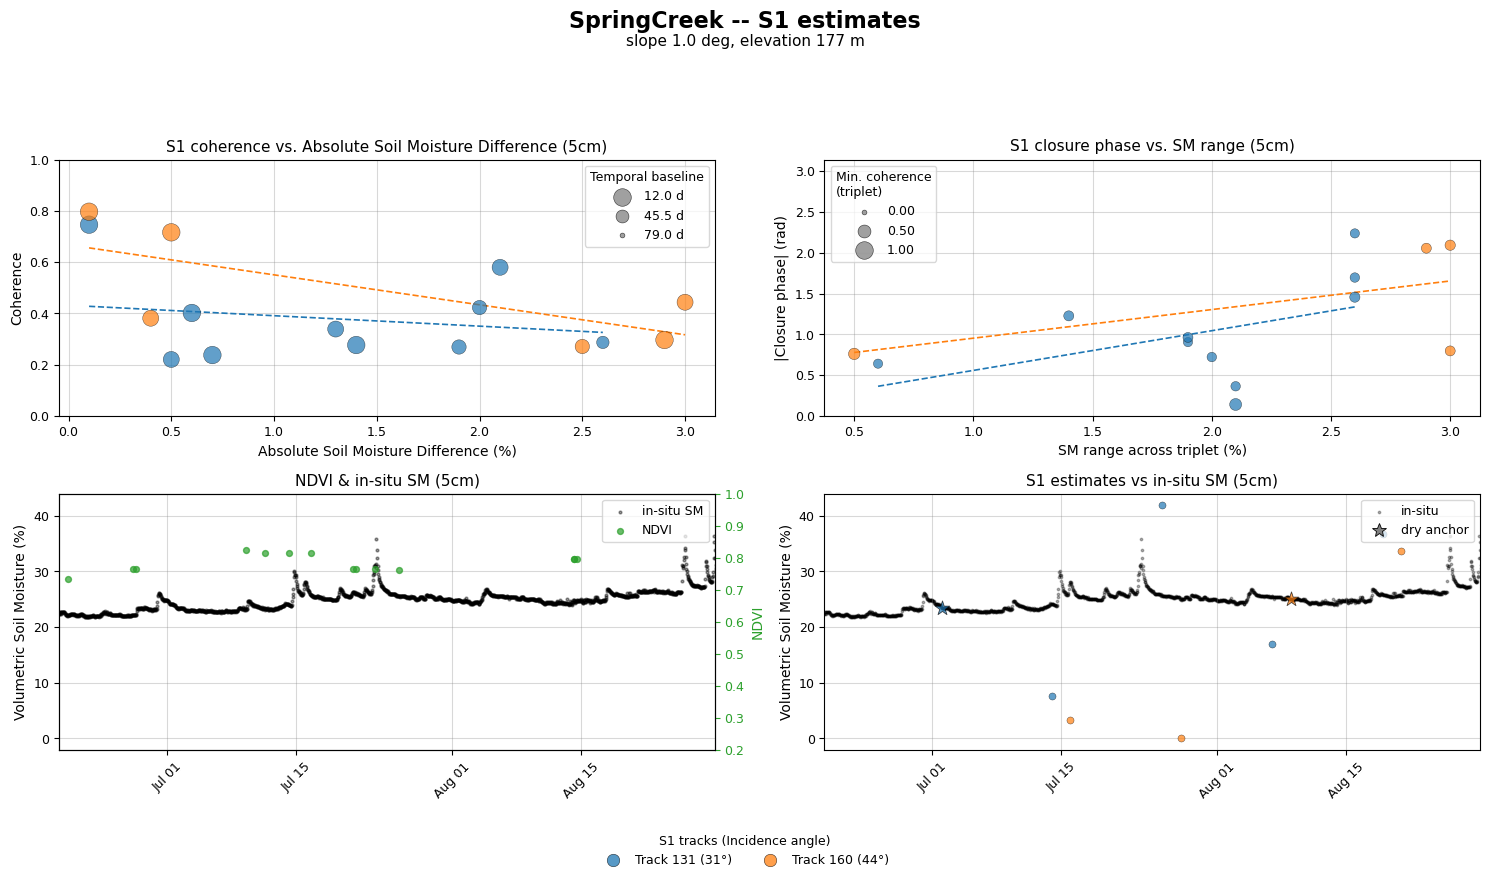

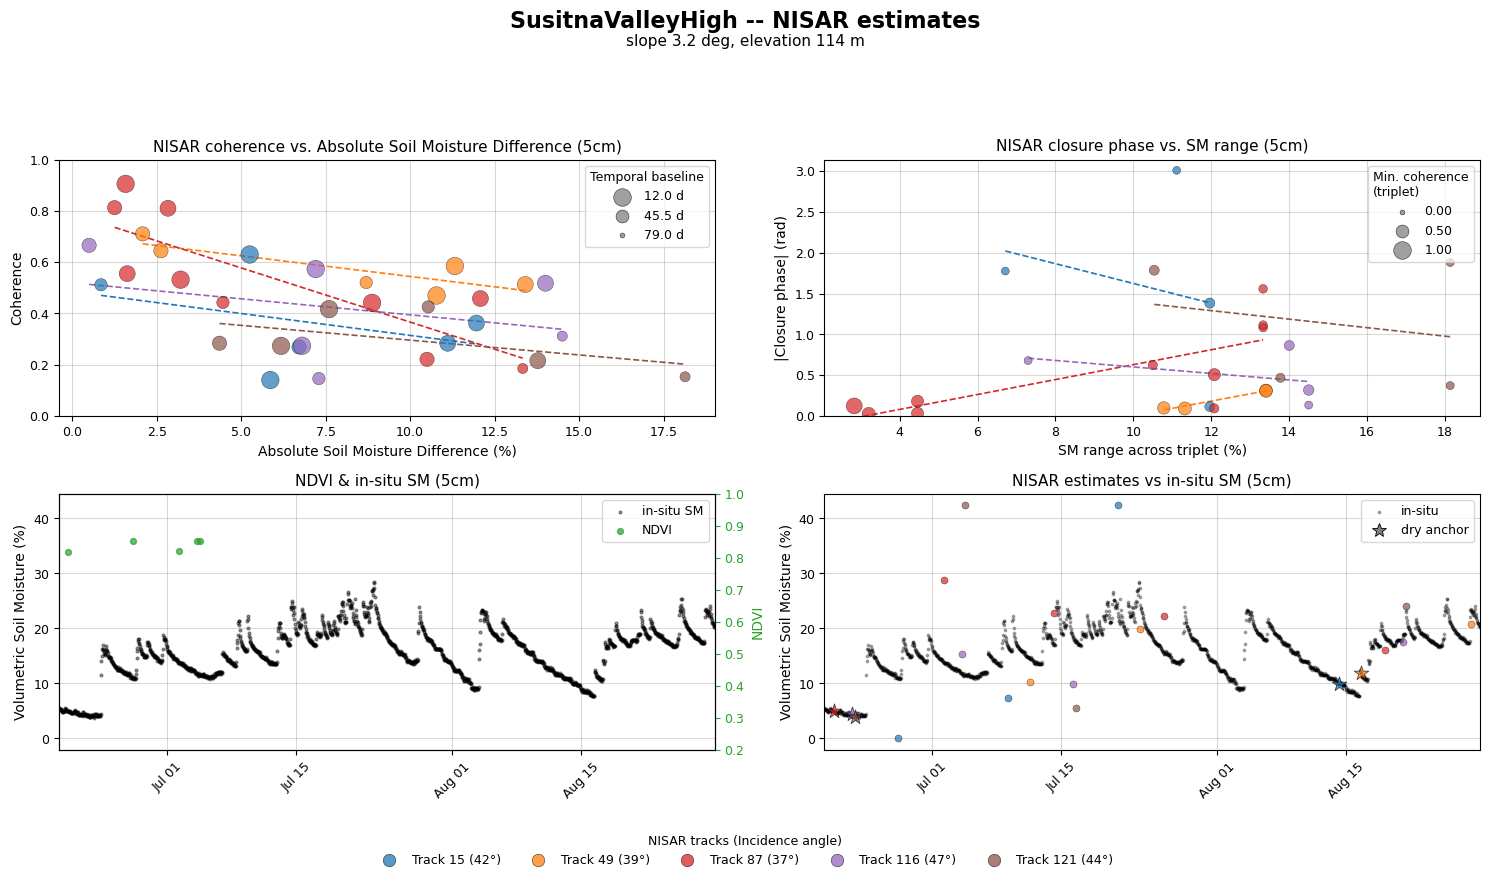

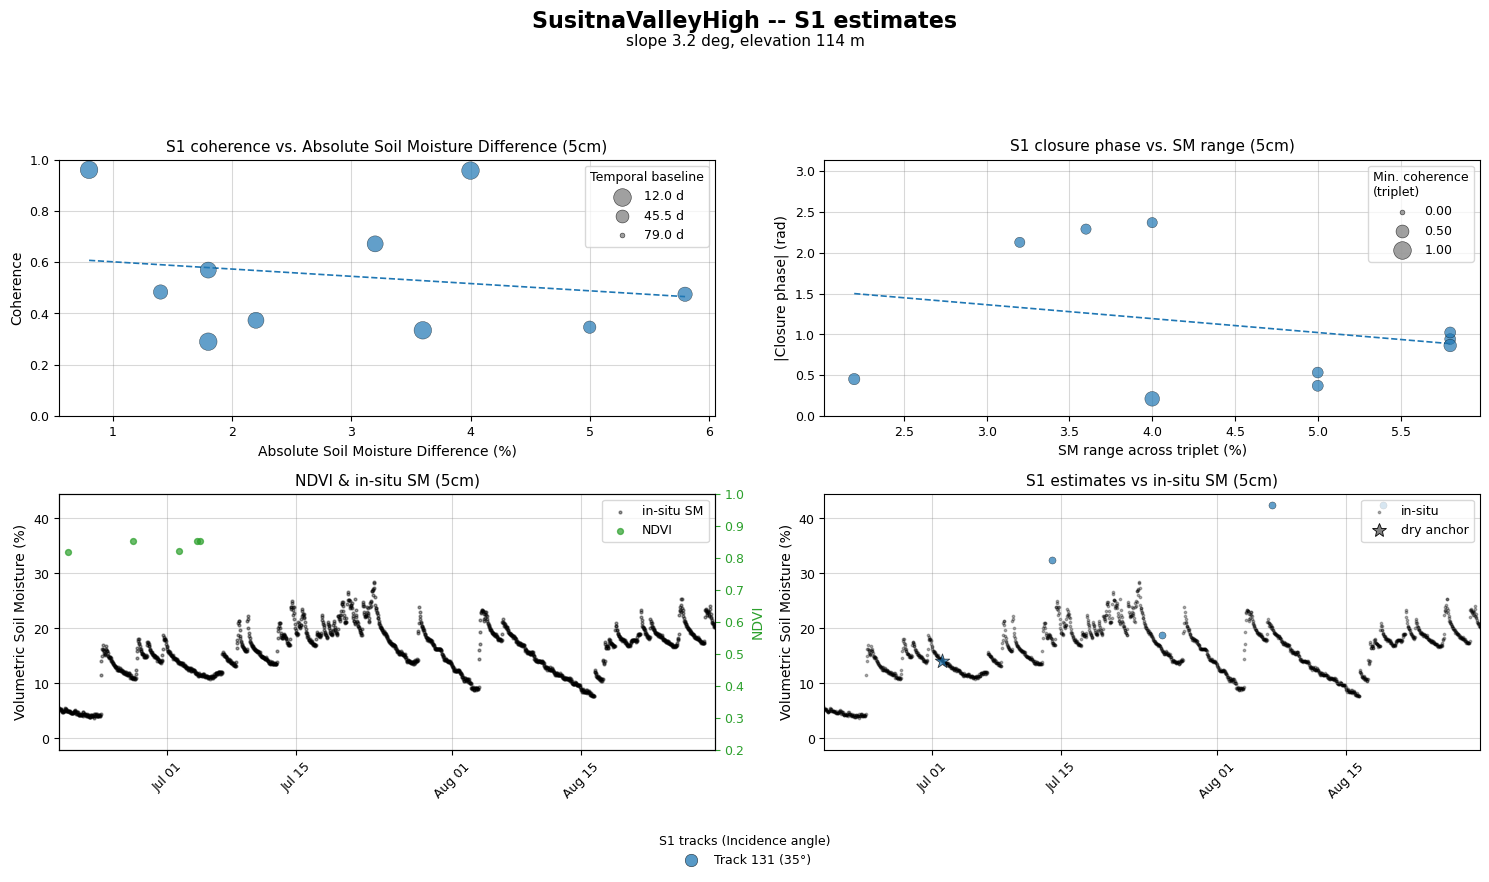

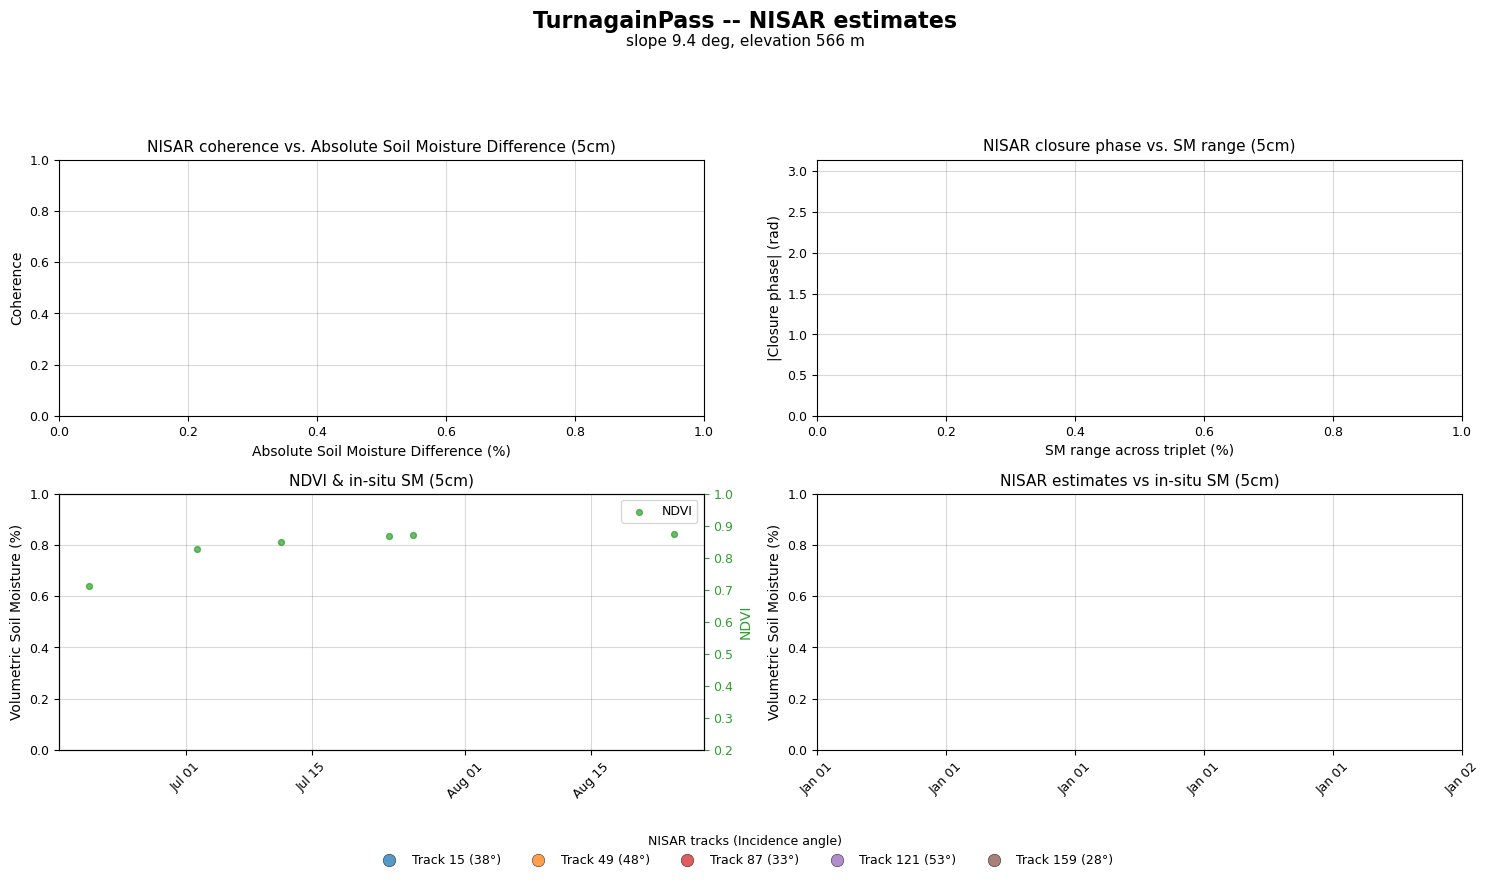

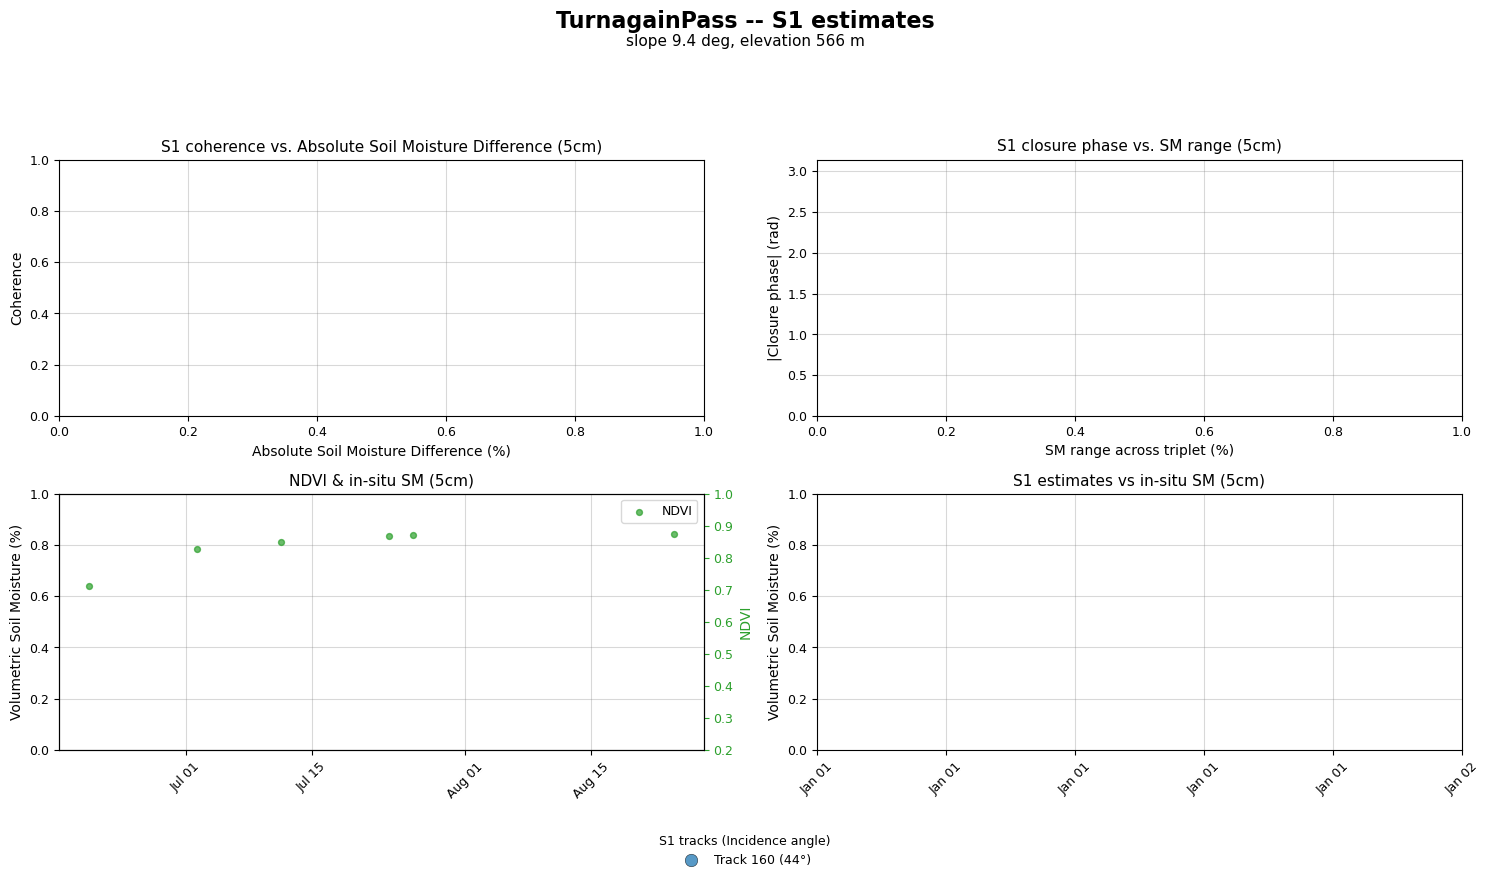

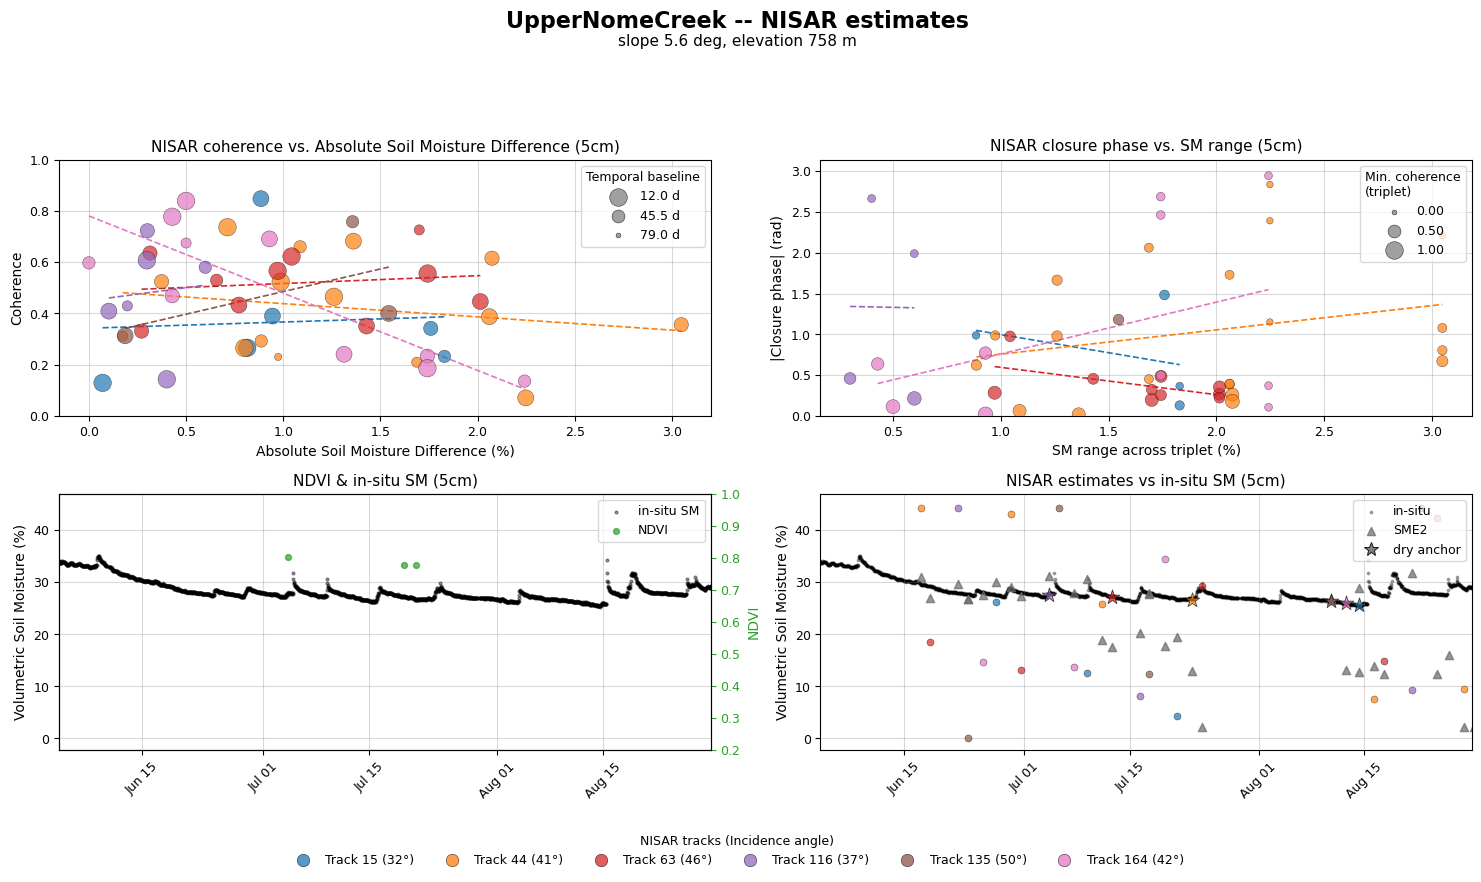

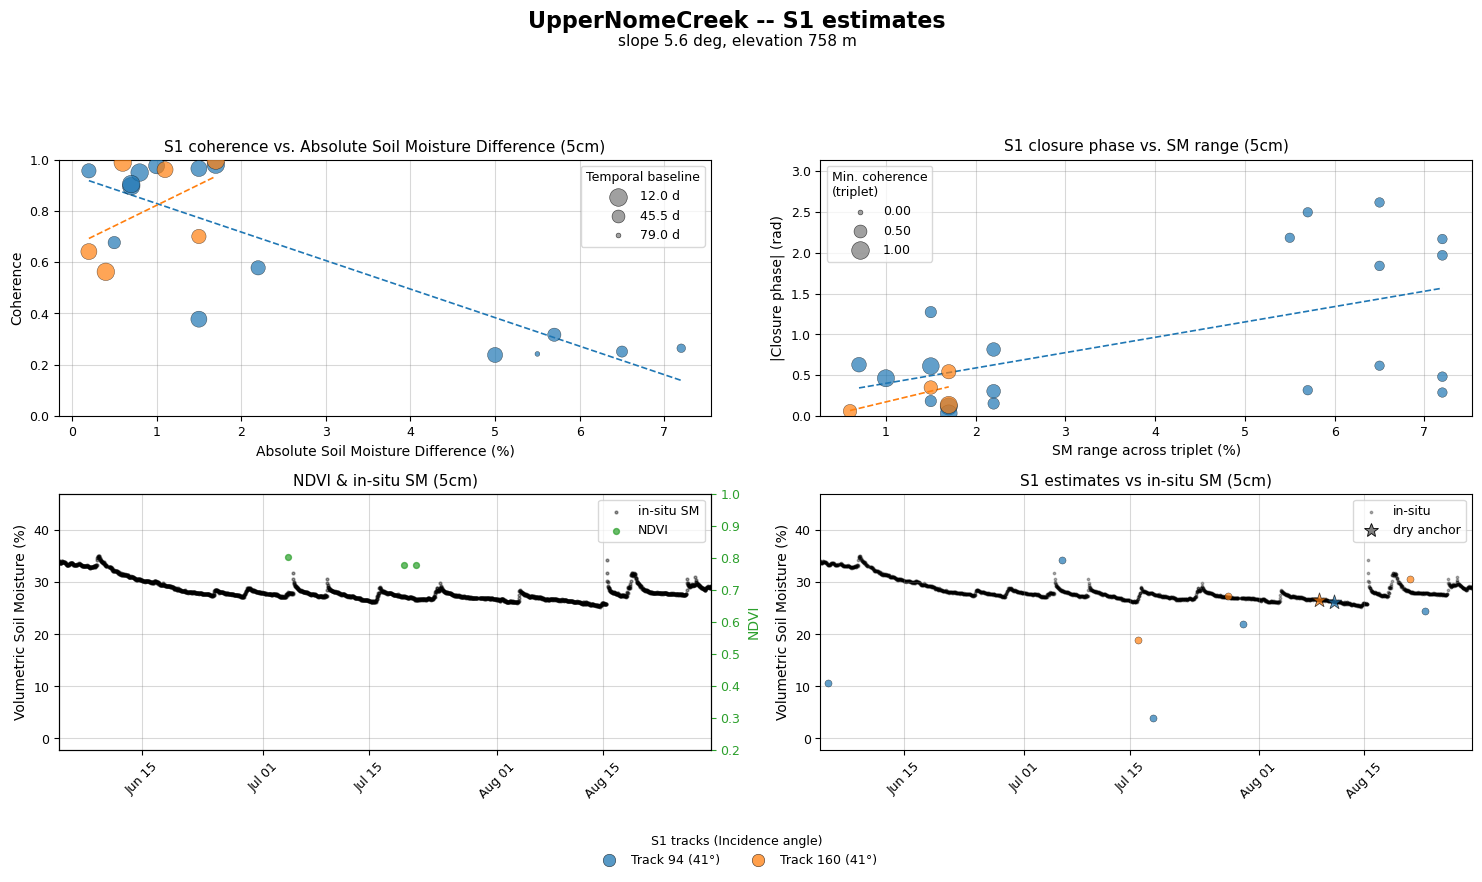

In [16]:
require_globals("stations_to_plot", "slope_by_station", "elevation_by_station")

import matplotlib.gridspec as gridspec

for station in stations_to_plot:
    series = read_insitu(station)
    has_ndvi = read_ndvi(station) is not None
    xlim = compute_station_xlim(station)
    slope = slope_by_station.get(station, np.nan)
    elev = elevation_by_station.get(station, np.nan)
    slope_str = f"{slope:.1f} deg" if not np.isnan(slope) else "n/a"
    elev_str = f"{elev:.0f} m" if not np.isnan(elev) else "n/a"

    pages = []  # (fig, ax_ndvi_or_None, ax_ts) -- built for both sensors before either is
                # shown, so their shared Volumetric Soil Moisture (%) axes can be synced
                # across the station's NISAR and S1 pages, not just within one page
    for sensor in ["NISAR", "S1"]:
        tracks = _sensor_all_tracks(station, sensor)
        if not tracks:
            continue
        color_map = build_track_color_map(tracks)
        incidence_by_track = _sensor_incidence_by_track(station, sensor)

        fig = plt.figure(figsize=(15, 9))
        # 2x4: each normal panel is 2 sub-columns wide (0:2 or 2:4), so a lone
        # timeseries panel with no NDVI to share the row can be centered at 1:3 --
        # same width as every other panel, just shifted to the row's middle,
        # rather than stretched to fill the whole row.
        gs = gridspec.GridSpec(2, 4, figure=fig)
        ax_coh, ax_clo = fig.add_subplot(gs[0, 0:2]), fig.add_subplot(gs[0, 2:4])
        if has_ndvi:
            ax_ndvi, ax_ts = fig.add_subplot(gs[1, 0:2]), fig.add_subplot(gs[1, 2:4])
        else:
            ax_ndvi, ax_ts = None, fig.add_subplot(gs[1, 1:3])

        plot_coherence_single(ax_coh, station, series, color_map, sensor)
        plot_closure_single(ax_clo, station, series, color_map, sensor)
        if has_ndvi:
            plot_ndvi_insitu(ax_ndvi, station, xlim)
        plot_estimate_timeseries_single(ax_ts, station, sensor, color_map, xlim)

        fig.suptitle(f"{station} -- {sensor} estimates", fontsize=FONT_SUPTITLE,
                     fontweight="bold", y=0.975)
        fig.text(0.5, 0.935, f"slope {slope_str}, elevation {elev_str}",
                 ha="center", fontsize=FONT_PANEL_TITLE, fontweight="normal")
        fig.tight_layout(rect=[0, 0.08, 1, 0.89])

        handles, labels = build_track_legend_handles(sensor, color_map, incidence_by_track)
        if handles:
            fig.legend(handles, labels, loc="lower center", ncol=min(len(labels), 6),
                       fontsize=FONT_LEGEND, title=f"{sensor} tracks (Incidence angle)",
                       title_fontsize=FONT_LEGEND, frameon=False, bbox_to_anchor=(0.5, 0.01))

        pages.append((fig, ax_ndvi if has_ndvi else None, ax_ts))

    sm_axes = [ax for _, ax_ndvi, ax_ts in pages for ax in (ax_ndvi, ax_ts)]
    sync_sm_ylim(sm_axes)

    for fig, _ax_ndvi, _ax_ts in pages:
        plt.show()


## Summary

Two pages per station in `stations_to_plot` (one per satellite, skipped
individually if that satellite has no coherence/closure/estimate data for
the station; stations with no NISAR/S1 5cm estimate at all are dropped
entirely -- see Section 5's printed list). NDVI, coherence, and
closure-phase axes are fixed (0.2-1, 0-1, 0-pi) for cross-panel
comparability, as is scatter-dot size (Section 6/8: temporal baseline in the
coherence panel, triplet minimum coherence in the closure panel, both
against a fixed range shared by every page); the NDVI and estimate-timeseries
panels' shared Volumetric Soil Moisture (%) axis is synced across a
station's NISAR and S1 pages too, not just within one page. Every other
axis auto-scales to that page's own data. Track colors are
consistent only within one station+satellite page (Section 7), not across
stations or between a station's NISAR and S1 pages. Track identity and
incidence angle live in the shared legend strip below the 2x2 grid instead
of the scatter plots' own legend. Re-run
`NISAR_SM_alaska.ipynb` / `S1_SM_alaska.ipynb` first (their Section 12
export cell) if you want the estimate-timeseries panels to reflect a fresh
inversion run.